# 病理结构化数据建模

1. 数据校验，检查数据格式是否正确。
3. 查看一些统计信息，检查数据时候存在异常点。
4. 正则化，将数据变化到服从 N~(0, 1)。
5. 通过相关系数，例如spearman、person等筛选出特征。
6. 构建训练集和测试集，这里使用的是随机划分，正常多中心验证，需要大家根据自己的场景构建两份数据。
7. 通过Lasso筛选特征，选取其中的非0项作为后续模型的特征。
8. 使用机器学习算法，例如LR、SVM、RF等进行任务学习。
9. 模型结果可视化，例如AUC、ROC曲线，混淆矩阵等。

In [1]:
import os
from IPython.display import display
from onekey_algo import OnekeyDS as okds
from onekey_algo import get_param_in_cwd

os.makedirs('img', exist_ok=True)
os.makedirs('results', exist_ok=True)
os.makedirs('features', exist_ok=True)

# 设置数据目录
task_type = 'Path'
# 对应的标签文件
group_info = get_param_in_cwd('dataset_column') or 'group'
labelf = get_param_in_cwd('label_file')
# 读取标签数据列名
labels = [get_param_in_cwd('task_column') or 'label']

In [2]:
from collections import namedtuple
import onekey_algo.custom.components as okcomp
from onekey_algo import OnekeyDS as okds
from onekey_algo.custom.utils import print_join_info
from onekey_algo import get_param_in_cwd

import pandas as pd
import numpy as np

# 读取数据，B超诊断阳性=1，bc_data.csv是要读取的数据。
import pandas as pd
import os
os.makedirs('img', exist_ok=True)
os.makedirs('features', exist_ok=True)

# 读取数据，B超诊断阳性=1，bc_data.csv是要读取的数据。
prob_histo = pd.read_csv('features/prob_histogram.csv')
prob_tfidf = pd.read_csv('features/prob_tfidf.csv')
prob = pd.merge(prob_histo, prob_tfidf, on='ID', how='inner', suffixes=['_histo', '_tfidf'])
prob['ID'] = prob['ID'].astype(str)

pred_histo = pd.read_csv('features/pred_histogram.csv')
pred_tfidf = pd.read_csv('features/pred_tfidf.csv')
pred = pd.merge(pred_histo, pred_tfidf, on='ID', how='inner', suffixes=['_histo', '_tfidf'])
pred['ID'] = pred['ID'].astype(str)

features = pd.merge(prob, pred, on='ID', how='inner')
features.to_csv('features/path_features.csv', index=False, header=True)
labels = ['label']
featrues_not_use = ['ID']

label_data = pd.read_csv(get_param_in_cwd('label_file'), header=0)[['ID', 'label', 'group']]
label_data['ID'] = label_data['ID'].map(lambda x: str(x).replace('.nii.gz', ''))
combined_data = pd.merge(features, label_data, on='ID', how='inner')
combined_data

,ID,prob-0.0,prob-0.01,prob-0.02,prob-0.03,prob-0.04,prob-0.05,prob-0.06,prob-0.07,prob-0.08,...,prob097,prob098,prob099,prob10,pred-0,pred-1,pred0,pred1,label,group
0,1,0.0,0.0,0.0,0.000,0.030,0.000,0.000,0.061,0.030,...,0.000,0.0,0.0,0.00,0.970,0.030,0.998,0.056,0,train
1,2,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.0,0.0,0.00,0.889,0.111,0.976,0.218,0,train
2,3,0.0,0.0,0.0,0.022,0.022,0.000,0.043,0.022,0.065,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
3,4,0.0,0.0,0.0,0.000,0.000,0.000,0.048,0.048,0.000,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
4,5,0.0,0.0,0.0,0.026,0.000,0.026,0.026,0.026,0.000,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
468,642,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.0,0.0,0.00,0.667,0.333,0.746,0.666,1,test2
469,643,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.0,0.0,0.68,0.857,0.143,0.958,0.285,1,test2
470,644,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.0,0.0,0.00,0.750,0.250,0.859,0.512,1,test2
471,645,0.0,0.0,0.0,0.000,0.000,0.100,0.000,0.000,0.000,...,0.354,0.0,0.0,0.00,0.500,0.500,0.489,0.873,1,test2


## 特征拼接 

将标注数据`label_data`与`rad_data`进行合并，得到训练数据。

**注意：需要删掉ID这一列**

In [3]:
from onekey_algo.custom.utils import print_join_info

ids = combined_data['ID']
combined_data = combined_data.drop(['ID'], axis=1)
print(combined_data[labels].value_counts())
combined_data

label
0        323
1        150
dtype: int64


,prob-0.0,prob-0.01,prob-0.02,prob-0.03,prob-0.04,prob-0.05,prob-0.06,prob-0.07,prob-0.08,prob-0.09,...,prob097,prob098,prob099,prob10,pred-0,pred-1,pred0,pred1,label,group
0,0.0,0.0,0.0,0.000,0.030,0.000,0.000,0.061,0.030,0.030,...,0.000,0.0,0.0,0.00,0.970,0.030,0.998,0.056,0,train
1,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.111,...,0.000,0.0,0.0,0.00,0.889,0.111,0.976,0.218,0,train
2,0.0,0.0,0.0,0.022,0.022,0.000,0.043,0.022,0.065,0.043,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
3,0.0,0.0,0.0,0.000,0.000,0.000,0.048,0.048,0.000,0.000,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
4,0.0,0.0,0.0,0.026,0.000,0.026,0.026,0.026,0.000,0.053,...,0.000,0.0,0.0,0.00,1.000,0.000,1.000,0.000,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
468,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.048,...,0.000,0.0,0.0,0.00,0.667,0.333,0.746,0.666,1,test2
469,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.143,...,0.000,0.0,0.0,0.68,0.857,0.143,0.958,0.285,1,test2
470,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.0,0.0,0.00,0.750,0.250,0.859,0.512,1,test2
471,0.0,0.0,0.0,0.000,0.000,0.100,0.000,0.000,0.000,0.000,...,0.354,0.0,0.0,0.00,0.500,0.500,0.489,0.873,1,test2


## 获取到数据的统计信息

1. count，统计样本个数。
2. mean、std, 对应特征的均值、方差
3. min, 25%, 50%, 75%, max，对应特征的最小值，25,50,75分位数，最大值。

In [4]:
combined_data.describe()

,prob-0.0,prob-0.01,prob-0.02,prob-0.03,prob-0.04,prob-0.05,prob-0.06,prob-0.07,prob-0.08,prob-0.09,...,prob096,prob097,prob098,prob099,prob10,pred-0,pred-1,pred0,pred1,label
count,4.730e+02,473.000,473.000,473.000,473.000,473.000,473.000,473.000,473.000,473.000,...,473.000,473.000,473.000,473.000,473.000,473.000,473.000,473.000,473.000,473.000
mean,4.687e-04,0.002,0.004,0.007,0.010,0.015,0.022,0.024,0.029,0.035,...,0.003,0.010,0.008,0.011,0.006,0.940,0.060,0.972,0.115,0.317
std,4.906e-03,0.010,0.017,0.021,0.026,0.032,0.040,0.043,0.046,0.050,...,0.043,0.068,0.058,0.071,0.052,0.100,0.100,0.084,0.188,0.466
min,0.000e+00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.333,0.000,0.270,0.000,0.000
25%,0.000e+00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.909,0.000,0.984,0.000,0.000
50%,0.000e+00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000
75%,0.000e+00,0.000,0.000,0.000,0.000,0.000,0.038,0.042,0.053,0.062,...,0.000,0.000,0.000,0.000,0.000,1.000,0.091,1.000,0.176,1.000
max,6.250e-02,0.105,0.111,0.200,0.214,0.167,0.263,0.333,0.250,0.267,...,0.731,0.751,0.560,0.712,0.680,1.000,0.667,1.000,0.963,1.000


## 正则化

`normalize_df` 为onekey中正则化的API，将数据变化到0均值1方差。正则化的方法为

$column = \frac{column - mean}{std}$

In [5]:
from onekey_algo.custom.components.comp1 import normalize_df
data = normalize_df(combined_data, not_norm=labels, group='group')
data = data.dropna(axis=1)
data.describe()

,prob-0.0,prob-0.01,prob-0.02,prob-0.03,prob-0.04,prob-0.05,prob-0.06,prob-0.07,prob-0.08,prob-0.09,...,prob095,prob097,prob098,prob099,prob10,pred-0,pred-1,pred0,pred1,label
count,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,...,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,473.000
mean,2.441e-17,-4.507e-17,-5.633e-18,3.756e-18,-2.441e-17,-3.004e-17,2.629e-17,-1.878e-17,1.878e-17,5.633e-18,...,-7.511e-18,-5.633e-18,4.694e-17,7.511e-18,1.878e-17,1.352e-16,2.629e-17,-8.187e-16,3.380e-17,0.317
std,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,...,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,0.466
min,-1.111e-01,-2.131e-01,-3.209e-01,-4.013e-01,-5.214e-01,-5.302e-01,-6.613e-01,-6.704e-01,-7.492e-01,-7.343e-01,...,-1.111e-01,-2.233e-01,-1.901e-01,-1.965e-01,-1.578e-01,-6.337e+00,-6.175e-01,-8.399e+00,-6.335e-01,0.000
25%,-1.040e-01,-2.131e-01,-3.209e-01,-4.013e-01,-5.214e-01,-5.302e-01,-6.613e-01,-6.704e-01,-6.651e-01,-7.343e-01,...,-1.025e-01,-1.738e-01,-1.319e-01,-1.965e-01,-1.311e-01,-2.780e-01,-6.130e-01,1.499e-01,-6.190e-01,0.000
50%,-1.040e-01,-1.434e-01,-2.242e-01,-3.821e-01,-2.642e-01,-3.959e-01,-4.689e-01,-5.187e-01,-5.746e-01,-7.146e-01,...,-1.025e-01,-1.738e-01,-1.319e-01,-1.536e-01,-1.311e-01,5.876e-01,-5.876e-01,2.972e-01,-6.170e-01,0.000
75%,-7.581e-02,-1.305e-01,-1.624e-01,-2.119e-01,-2.642e-01,-3.959e-01,4.876e-01,5.454e-01,5.701e-01,6.208e-01,...,-9.448e-02,-9.590e-02,-1.319e-01,-1.305e-01,-9.495e-02,6.130e-01,2.780e-01,3.403e-01,2.973e-01,1.000
max,1.312e+01,8.841e+00,8.371e+00,1.017e+01,6.545e+00,4.482e+00,4.377e+00,4.818e+00,5.136e+00,4.313e+00,...,1.205e+01,1.083e+01,9.496e+00,1.022e+01,1.180e+01,6.175e-01,6.337e+00,4.326e-01,4.877e+00,1.000


### 相关系数

计算相关系数的方法有3种可供选择
1. pearson （皮尔逊相关系数）: standard correlation coefficient

2. kendall (肯德尔相关性系数) : Kendall Tau correlation coefficient

3. spearman (斯皮尔曼相关性系数): Spearman rank correlation

三种相关系数参考：https://blog.csdn.net/zmqsdu9001/article/details/82840332

In [6]:
pearson_corr = data[data['group'] == 'train'][[c for c in data.columns if c not in labels]].corr('pearson')
# kendall_corr = data[[c for c in data.columns if c not in labels]].corr('kendall')
# spearman_corr = data[[c for c in data.columns if c not in labels]].corr('spearman')

### 相关系数可视化

通过修改变量名，可以可视化不同相关系数下的相关矩阵。

**注意**：当特征特别多的时候（大于100），尽量不要可视化，否则运行时间会特别长。

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from onekey_algo.custom.components.comp1 import draw_matrix

if combined_data.shape[1] < 100:
    plt.figure(figsize=(50.0, 40.0))
    # 选择可视化的相关系数
    draw_matrix(pearson_corr, annot=True, cmap='YlGnBu', cbar=False)
    plt.savefig(f'img/feature_corr.svg', bbox_inches = 'tight')

### 聚类分析

通过修改变量名，可以可视化不同相关系数下的相聚类分析矩阵。

注意：当特征特别多的时候（大于100），尽量不要可视化，否则运行时间会特别长。

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

if combined_data.shape[1] < 100:
    pp = sns.clustermap(pearson_corr, linewidths=.5, figsize=(50.0, 40.0), cmap='YlGnBu')
    plt.setp(pp.ax_heatmap.get_yticklabels(), rotation=0)
    plt.savefig(f'img/feature_cluster.svg', bbox_inches = 'tight')

### 特征筛选 -- 相关系数

根据相关系数，对于相关性比较高的特征（一般文献取corr>0.9），两者保留其一。

```python
def select_feature(corr, threshold: float = 0.9, keep: int = 1, topn=10, verbose=False):
    """
    * corr, 相关系数矩阵。
    * threshold，筛选的相关系数的阈值，大于阈值的两者保留其一（可以根据keep修改，可以是其二...）。默认阈值为0.9
    * keep，可以选择大于相关系数，保留几个，默认只保留一个。
    * topn, 每次去掉多少重复特征。
    * verbose，是否打印日志
    """
```

In [9]:
from onekey_algo.custom.components.comp1 import select_feature
sel_feature = select_feature(pearson_corr, threshold=0.9, topn=32, verbose=False)

sel_feature = sel_feature + labels + ['group']
sel_feature

['prob-0.33',
 'prob-0.34',
 'prob-0.45',
 'prob-0.46',
 'prob-0.49',
 'prob00',
 'prob001',
 'prob002',
 'prob003',
 'prob004',
 'prob005',
 'prob006',
 'prob007',
 'prob008',
 'prob009',
 'prob01',
 'prob011',
 'prob012',
 'prob013',
 'prob014',
 'prob015',
 'prob016',
 'prob017',
 'prob018',
 'prob019',
 'prob02',
 'prob021',
 'prob022',
 'prob023',
 'prob024',
 'prob025',
 'prob026',
 'prob027',
 'prob028',
 'prob029',
 'prob03',
 'prob031',
 'prob032',
 'prob033',
 'prob034',
 'prob035',
 'prob036',
 'prob037',
 'prob038',
 'prob039',
 'prob04',
 'prob041',
 'prob042',
 'prob043',
 'prob044',
 'prob045',
 'prob046',
 'prob047',
 'prob048',
 'prob049',
 'prob05',
 'prob051',
 'prob052',
 'prob054',
 'prob056',
 'prob059',
 'prob06',
 'prob061',
 'prob067',
 'prob068',
 'prob073',
 'prob075',
 'prob077',
 'prob083',
 'prob084',
 'prob085',
 'prob087',
 'prob088',
 'prob089',
 'prob091',
 'prob092',
 'prob093',
 'prob094',
 'prob095',
 'prob097',
 'prob098',
 'prob099',
 'prob10',
 '

### 过滤特征

通过`sel_feature`过滤出筛选出来的特征。

In [10]:
sel_data = data[sel_feature]
sel_data.describe()

,prob-0.33,prob-0.34,prob-0.45,prob-0.46,prob-0.49,prob00,prob001,prob002,prob003,prob004,...,prob093,prob094,prob095,prob097,prob098,prob099,prob10,pred0,pred1,label
count,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,...,473.000,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,4.730e+02,473.000
mean,3.169e-17,-4.882e-17,-8.450e-18,-8.450e-18,1.221e-17,-1.127e-17,2.629e-17,-4.694e-17,-2.253e-17,-3.380e-17,...,0.000,3.756e-18,-7.511e-18,-5.633e-18,4.694e-17,7.511e-18,1.878e-17,-8.187e-16,3.380e-17,0.317
std,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,...,0.998,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,9.979e-01,0.466
min,-4.636e-01,-4.451e-01,-2.325e-01,-2.432e-01,-2.335e-01,-1.132e-01,-2.256e-01,-3.348e-01,-4.153e-01,-5.479e-01,...,-0.183,-1.581e-01,-1.111e-01,-2.233e-01,-1.901e-01,-1.965e-01,-1.578e-01,-8.399e+00,-6.335e-01,0.000
25%,-4.636e-01,-4.451e-01,-2.325e-01,-2.016e-01,-2.335e-01,-1.132e-01,-2.256e-01,-3.348e-01,-4.153e-01,-5.479e-01,...,-0.103,-1.305e-01,-1.025e-01,-1.738e-01,-1.319e-01,-1.965e-01,-1.311e-01,1.499e-01,-6.190e-01,0.000
50%,-4.085e-01,-4.386e-01,-2.206e-01,-2.016e-01,-1.842e-01,-1.111e-01,-1.511e-01,-2.234e-01,-3.897e-01,-2.809e-01,...,-0.103,-1.305e-01,-1.025e-01,-1.738e-01,-1.319e-01,-1.536e-01,-1.311e-01,2.972e-01,-6.170e-01,0.000
75%,-3.212e-01,-2.766e-01,-1.823e-01,-1.668e-01,-1.467e-01,-7.581e-02,-1.306e-01,-1.646e-01,-2.442e-01,-2.809e-01,...,-0.093,-1.163e-01,-9.448e-02,-9.590e-02,-1.319e-01,-1.305e-01,-9.495e-02,3.403e-01,2.973e-01,1.000
max,8.599e+00,8.011e+00,1.109e+01,1.138e+01,1.134e+01,1.312e+01,8.819e+00,7.720e+00,8.184e+00,4.960e+00,...,12.631,1.025e+01,1.205e+01,1.083e+01,9.496e+00,1.022e+01,1.180e+01,4.326e-01,4.877e+00,1.000


## 构建数据

将样本的训练数据X与监督信息y分离出来，并且对训练数据进行划分，一般的划分原则为80%-20%

In [11]:
import numpy as np
import onekey_algo.custom.components as okcomp
from collections import OrderedDict
n_classes = 2
train_data = sel_data[(sel_data[group_info] == 'train')]
train_ids = ids[train_data.index]
train_data = train_data.reset_index()
train_data = train_data.drop('index', axis=1)
y_data = train_data[labels]
X_data = train_data.drop(labels + [group_info], axis=1)

subsets = [s for s in get_param_in_cwd('subsets') if s != 'train']
val_datasets = OrderedDict()
for subset in subsets:
    val_data = sel_data[sel_data[group_info] == subset]
    val_ids = ids[val_data.index]
    val_data = val_data.reset_index()
    val_data = val_data.drop('index', axis=1)
    y_val_data = val_data[labels]
    X_val_data = val_data.drop(labels + [group_info], axis=1)
    val_datasets[subset] = [X_val_data, y_val_data, val_ids]

y_all_data = sel_data[labels]
X_all_data = sel_data.drop(labels + [group_info], axis=1)

column_names = X_data.columns
print(f"训练集样本数：{X_data.shape}，", '，'.join([f"{subset}样本数：{d_[0].shape}" for subset, d_ in val_datasets.items()]))

训练集样本数：(218, 85)， test1样本数：(174, 85)，test2样本数：(81, 85)


### Lasso

初始化Lasso模型，alpha为惩罚系数。具体的参数文档可以参考：[文档](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html?highlight=lasso#sklearn.linear_model.Lasso)

### 交叉验证

不同Lambda下的，特征的的权重大小。
```python
def lasso_cv_coefs(X_data, y_data, points=50, column_names: List[str] = None, **kwargs):
    """

    Args:
        X_data: 训练数据
        y_data: 监督数据
        points: 打印多少个点。默认50
        column_names: 列名，默认为None，当选择的数据很多的时候，建议不要添加此参数
        **kwargs: 其他用于打印控制的参数。

    """
 ```

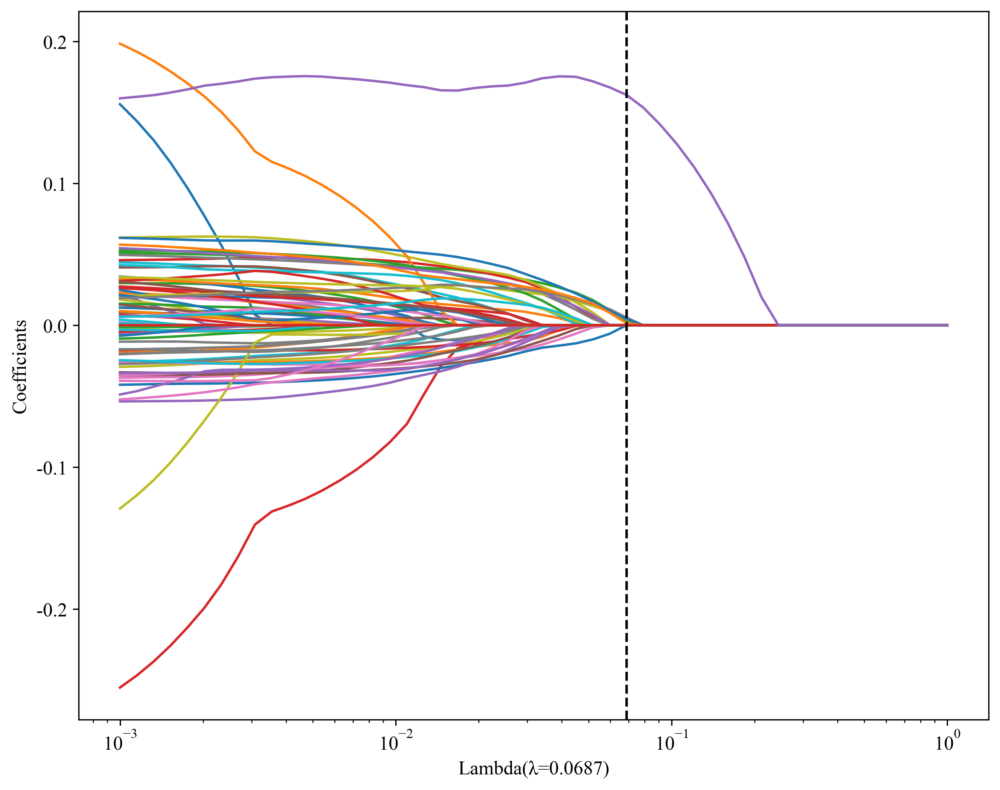

In [12]:
alpha = okcomp.comp1.lasso_cv_coefs(X_data, y_data, column_names=None, alpha_logmin=-3)
plt.savefig(f'img/{task_type}_feature_lasso.svg', bbox_inches = 'tight')

### 模型效能

```python
def lasso_cv_efficiency(X_data, y_data, points=50, **kwargs):
    """

    Args:
        Xdata: 训练数据
        ydata: 测试数据
        points: 打印的数据密度
        **kwargs: 其他的图像样式
            # 数据点标记, fmt="o"
            # 数据点大小, ms=3
            # 数据点颜色, mfc="r"
            # 数据点边缘颜色, mec="r"
            # 误差棒颜色, ecolor="b"
            # 误差棒线宽, elinewidth=2
            # 误差棒边界线长度, capsize=2
            # 误差棒边界厚度, capthick=1
    Returns:
    """
 ```

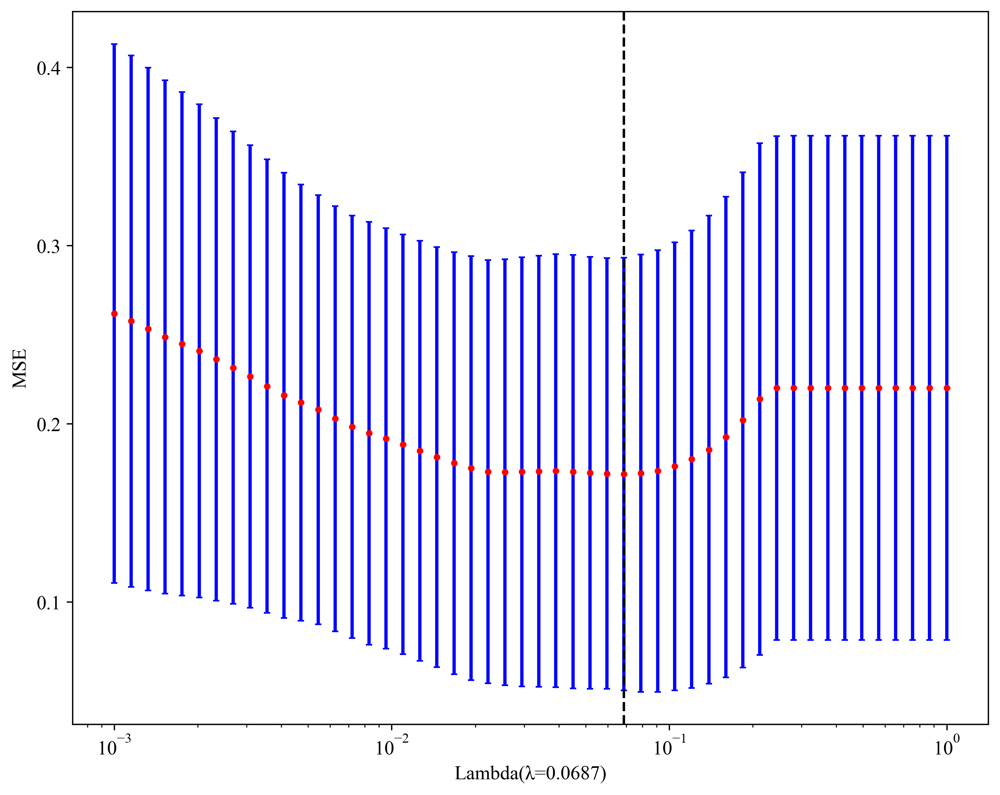

In [13]:
okcomp.comp1.lasso_cv_efficiency(X_data, y_data, points=50, alpha_logmin=-3)
plt.savefig(f'img/{task_type}_feature_mse_label.svg', bbox_inches = 'tight')

### 惩罚系数

使用交叉验证的惩罚系数作为模型训练的基础。

In [14]:
from sklearn import linear_model

models = []
for label in labels:
    clf = linear_model.Lasso(alpha=alpha)
    clf.fit(X_data, y_data[label])
    models.append(clf)

### 特征筛选

筛选出其中coef > 0的特征。并且打印出相应的公式。

In [15]:
COEF_THRESHOLD = 1e-8 # 筛选的特征阈值
scores = []
selected_features = []
for label, model in zip(labels, models):
    feat_coef = [(feat_name, coef) for feat_name, coef in zip(column_names, model.coef_) 
                 if COEF_THRESHOLD is None or abs(coef) > COEF_THRESHOLD]
    selected_features.append([feat for feat, _ in feat_coef])
    formula = ' '.join([f"{coef:+.6f} * {feat_name}" for feat_name, coef in feat_coef])
    score = f"{label} = {model.intercept_} {'+' if formula[0] != '-' else ''} {formula}"
    scores.append(score)
    
print(scores[0])

label = 0.28440366972477066 + +0.002680 * prob027 +0.004292 * prob083 +0.005413 * prob094 +0.004530 * prob098 +0.001547 * prob099 +0.162381 * pred1


### 特征权重

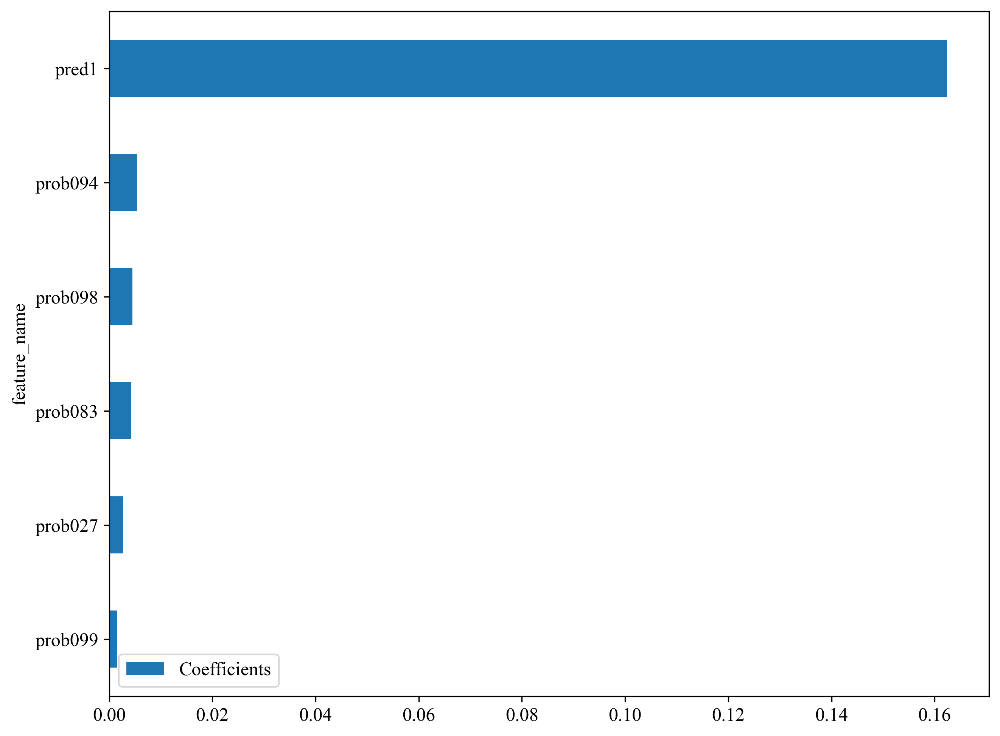

In [16]:
feat_coef = sorted(feat_coef, key=lambda x: x[1])
feat_coef_df = pd.DataFrame(feat_coef, columns=['feature_name', 'Coefficients'])
feat_coef_df.plot(x='feature_name', y='Coefficients', kind='barh')

plt.savefig(f'img/{task_type}_feature_weights.svg', bbox_inches = 'tight')

### 进一步筛选特征

使用Lasso筛选出来的Coefficients比较高的特征作为训练数据。

In [17]:
X_data = X_data[selected_features[0]]
for subset in val_datasets:
    val_datasets[subset][0] = val_datasets[subset][0][selected_features[0]]
pd.concat([ids, combined_data[selected_features[0]]], axis=1).to_csv(f'features/{task_type}_after_lasso.csv', index=False)
X_data.columns

Index(['prob027', 'prob083', 'prob094', 'prob098', 'prob099', 'pred1'], dtype='object')

## 模型筛选

根据筛选出来的数据，做模型的初步选择。当前主要使用到的是Onekey中的

1. SVM，支持向量机，引用参考。
2. KNN，K紧邻，引用参考。
3. Decision Tree，决策树，引用参考。
4. Random Forests, 随机森林，引用参考。
5. XGBoost, bosting方法。引用参考。
6. LightGBM, bosting方法，引用参考。

In [18]:
model_names = get_param_in_cwd('ml_models', ['LR', 'SVM', 'RandomForest'])
models = okcomp.comp1.create_clf_model(model_names)
model_names = list(models.keys())

### 交叉验证

`n_trails`指定随机次数，每次采用的是80%训练，随机20%进行测试，找到最好的模型，以及对应的最好的数据划分。

```python
def get_bst_split(X_data: pd.DataFrame, y_data: pd.DataFrame,
            models: dict, test_size=0.2, metric_fn=accuracy_score, n_trails=10,
            cv: bool = False, shuffle: bool = False, metric_cut_off: float = None, random_state=None):
    """
    寻找数据集中最好的数据划分。
    Args:
        X_data: 训练数据
        y_data: 监督数据
        models: 模型名称，Dict类型、
        test_size: 测试集比例
        metric_fn: 评价模型好坏的函数，默认准确率，可选roc_auc_score。
        n_trails: 尝试多少次寻找最佳数据集划分。
        cv: 是否是交叉验证，默认是False，当为True时，n_trails为交叉验证的n_fold
        shuffle: 是否进行随机打乱
        metric_cut_off: 当metric_fn的值达到多少时进行截断。
        random_state: 随机种子

    Returns: {'max_idx': max_idx, "max_model": max_model, "max_metric": max_metric, "results": results}

    """
```

**注意：这里采用了【挑数据】，如果想要严谨，请修改`n_trails=1`。**

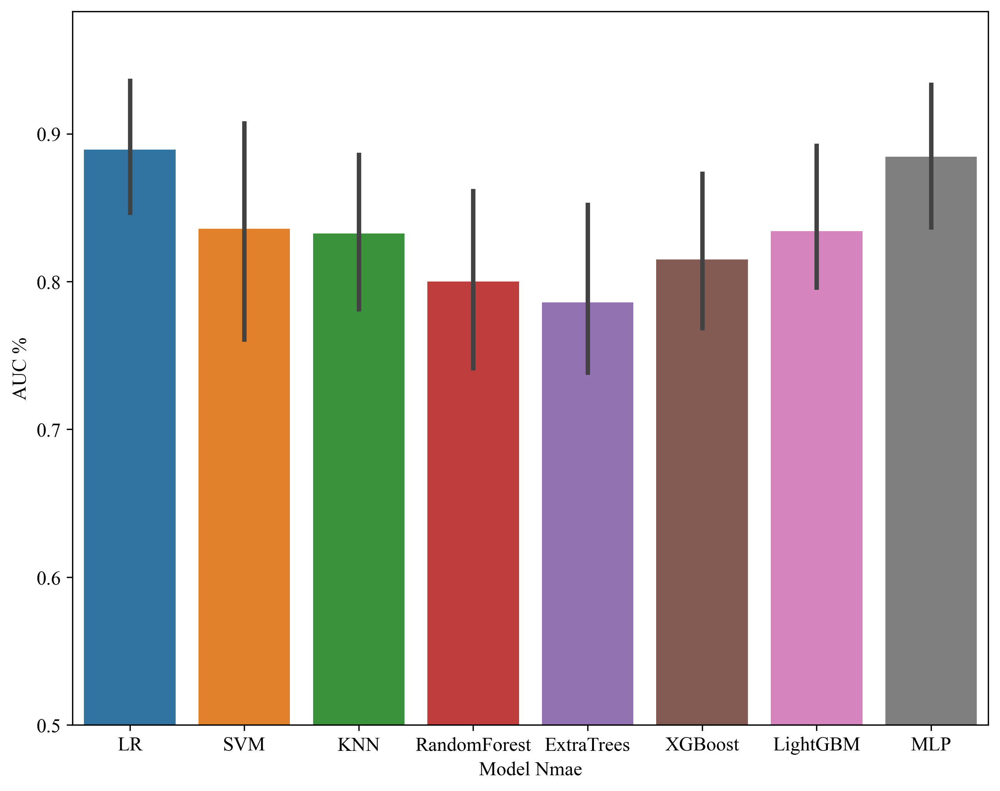

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score

# 随机使用n_trails次数据划分，找到最好的一次划分方法，并且保存在results中。
results = okcomp.comp1.get_bst_split(X_data, y_data, models, test_size=0.2, metric_fn=roc_auc_score, n_trails=5, cv=False, 
                                     random_state=75)
# _, (X_train_sel, X_test_sel, y_train_sel, y_test_sel) = results['results'][results['max_idx']]
trails, _ = zip(*results['results'])
cv_results = pd.DataFrame(trails, columns=model_names)
# 可视化每个模型在不同的数据划分中的效果。
sns.barplot(data=cv_results)
plt.ylabel('AUC %')
plt.xlabel('Model Nmae')
# plt.xticks(rotation=90)
plt.ylim(0.5,)
plt.savefig(f'img/{task_type}_model_cv.svg', bbox_inches = 'tight')

## 模型筛选

使用最好的数据划分，进行后续的模型研究。

**注意**: 一般情况下论文使用的是随机划分的数据，但也有些论文使用【刻意】筛选的数据划分。

In [20]:
import joblib
from onekey_algo.custom.components.comp1 import plot_feature_importance, smote_resample
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression

targets = []
os.makedirs('models', exist_ok=True)
for l in labels:
    new_models = okcomp.comp1.create_clf_model(model_names)
#     new_models['LR'] = LogisticRegression(penalty='l2', max_iter=8, C=0.8)
#     new_models['LightGBM'] = LGBMClassifier(n_estimators=1, max_depth=2, random_state=0)
#     new_models['RandomForest'] = RandomForestClassifier(n_estimators=7, max_depth=4, min_samples_split=2, random_state=0)
#     new_models['ExtraTrees'] = ExtraTreesClassifier(n_estimators=8, max_depth=2, min_samples_split=2, random_state=0)
#     new_models['XGBoost'] = XGBClassifier(n_estimators=1, objective='binary:logistic', max_depth=2, min_child_weight=.2,
#                                               use_label_encoder=False, eval_metric='error')
    model_names = list(new_models.keys())
    new_models = list(new_models.values())
    for mn, m in zip(model_names, new_models):        
        X_train_sel, y_train_sel = X_data, y_data
        if get_param_in_cwd('use_smote', False):
            X_train_sel, y_train_sel = smote_resample(X_train_sel, y_train_sel)
        m.fit(X_train_sel, y_train_sel[l])
        # 保存训练的模型
#         joblib.dump(m, f'models/{task_type}_{mn}_{l}.pkl') 
        # 输出模型特征重要性，只针对高级树模型有用
#         plot_feature_importance(m, selected_features[0], save_dir='img', prefix=f"{task_type}_")
    targets.append(new_models)

## 预测结果

* predictions，二维数据，每个label对应的每个模型的预测结果。
* pred_scores，二维数据，每个label对应的每个模型的预测概率值。

In [21]:
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from onekey_algo.custom.components.delong import calc_95_CI
from onekey_algo.custom.components.metrics import analysis_pred_binary

metric = []
pred_sel_idx = []
X_train_sel, y_train_sel = X_data, y_data
predictions = [[(model.predict(X_train_sel), 
                 [(model.predict(X_val_sel), y_val_sel) for X_val_sel, y_val_sel, _ in val_datasets.values()])  
                for model in target] for label, target in zip(labels, targets)]
pred_scores = [[(model.predict_proba(X_train_sel), 
                 [(model.predict_proba(X_val_sel), y_val_sel) for X_val_sel, y_val_sel, _ in val_datasets.values()]) 
                for model in target] for label, target in zip(labels, targets)]

for label, prediction, scores in zip(labels, predictions, pred_scores):
    for mname, (train_pred, val_preds), (train_score, val_scores) in zip(model_names, prediction, scores):
        # 计算训练集指数
        acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres = analysis_pred_binary(y_train_sel[label], 
                                                                                              train_score[:, 1])
        ci = f"{ci[0]:.3f} - {ci[1]:.3f}"
        metric.append((mname, acc, auc, ci, tpr, tnr, ppv, npv, thres, f"train"))
        for subset, (val_score, y_val_sel) in zip(val_datasets.keys(), val_scores):
            acc, auc, ci, tpr, tnr, ppv, npv, precision, recall, f1, thres = analysis_pred_binary(y_val_sel[label], 
                                                                                                  val_score[:, 1])
            ci = f"{ci[0]:.3f} - {ci[1]:.3f}"
            metric.append((mname, acc, auc, ci, tpr, tnr, ppv, npv, thres, subset))
metric = pd.DataFrame(metric, index=None, columns=['model_name', 'Accuracy', 'AUC', '95% CI',
                                                   'Sensitivity', 'Specificity', 'PPV', 'NPV', 'Threshold', 'Cohort'])
metric[['model_name', 'Accuracy', 'AUC', '95% CI', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'Cohort']].to_csv('results/Path_metrics.csv',
                                                                                                            index=False)
metric

,model_name,Accuracy,AUC,95% CI,Sensitivity,Specificity,PPV,NPV,Threshold,Cohort
0,LR,0.853,0.831,0.762 - 0.899,0.629,0.942,0.812,0.865,0.392,train
1,LR,0.770,0.770,0.691 - 0.849,0.732,0.788,0.621,0.861,0.224,test1
2,LR,0.840,0.859,0.773 - 0.946,0.812,0.857,0.788,0.875,0.198,test2
3,SVM,0.862,0.804,0.730 - 0.879,0.694,0.929,0.796,0.884,0.299,train
4,SVM,0.730,0.729,0.645 - 0.812,0.661,0.763,0.569,0.826,0.146,test1
5,SVM,0.790,0.785,0.675 - 0.896,0.750,0.816,0.727,0.833,0.140,test2
6,KNN,0.858,0.884,0.830 - 0.938,0.790,0.885,0.731,0.914,0.400,train
7,KNN,0.690,0.739,0.660 - 0.817,0.714,0.678,0.513,0.833,0.200,test1
8,KNN,0.778,0.793,0.695 - 0.891,0.719,0.816,0.719,0.816,0.200,test2
9,RandomForest,0.936,0.959,0.933 - 0.986,0.887,0.955,0.887,0.955,0.400,train


### 绘制曲线

绘制的不同模型的准确率柱状图和折线图曲线。

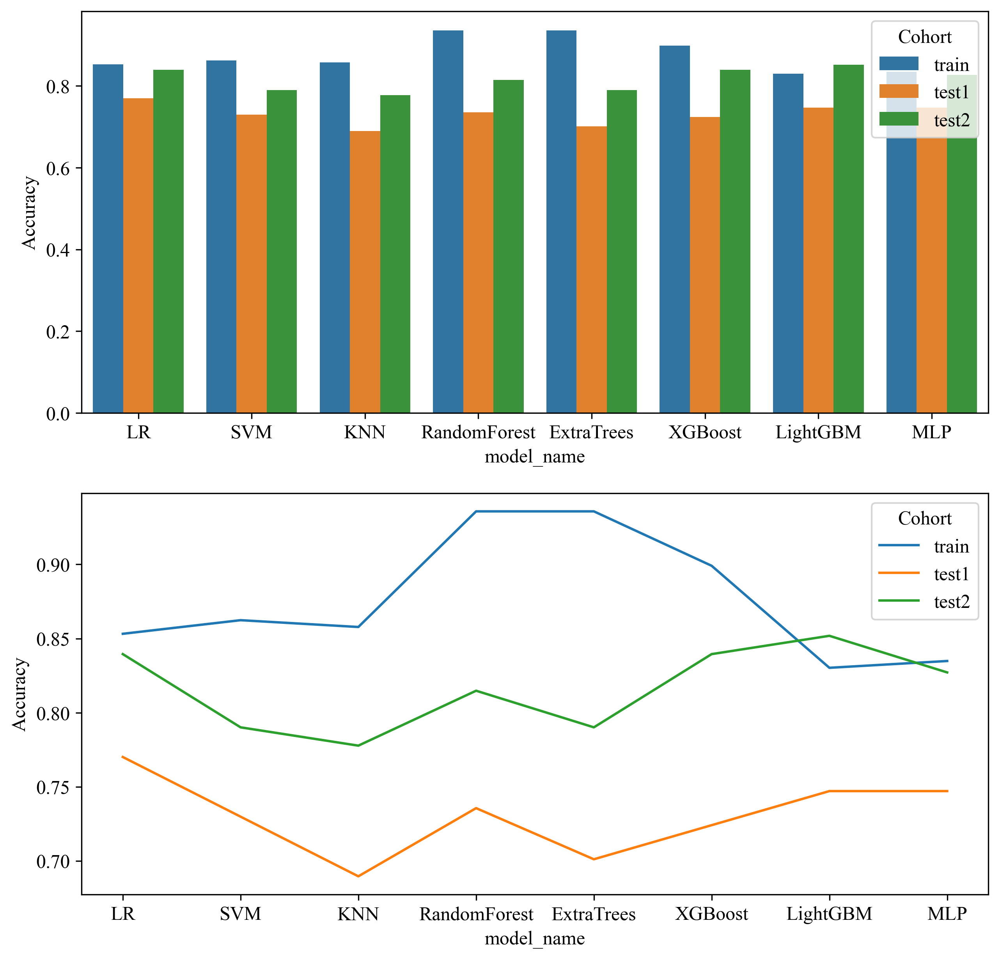

In [22]:
import seaborn as sns

plt.figure(figsize=(10, 10))
plt.subplot(211)
sns.barplot(x='model_name', y='Accuracy', data=metric, hue='Cohort')
plt.subplot(212)
sns.lineplot(x='model_name', y='Accuracy', data=metric, hue='Cohort')
plt.savefig(f'img/{task_type}_model_acc.svg', bbox_inches = 'tight')

### 绘制ROC曲线
确定最好的模型，并且绘制曲线。

```python
def draw_roc(y_test, y_score, title='ROC', labels=None):
```

`sel_model = ['SVM', 'KNN']`参数为想要绘制的模型对应的参数。

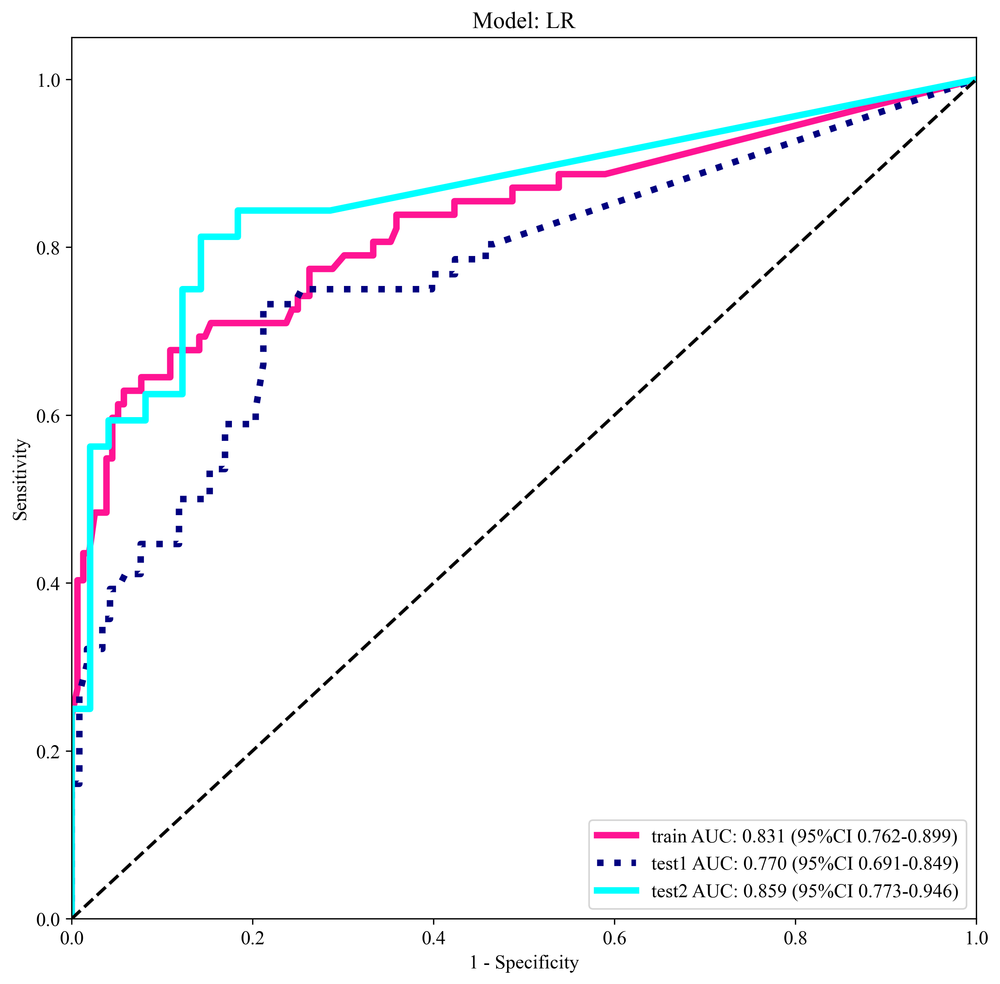

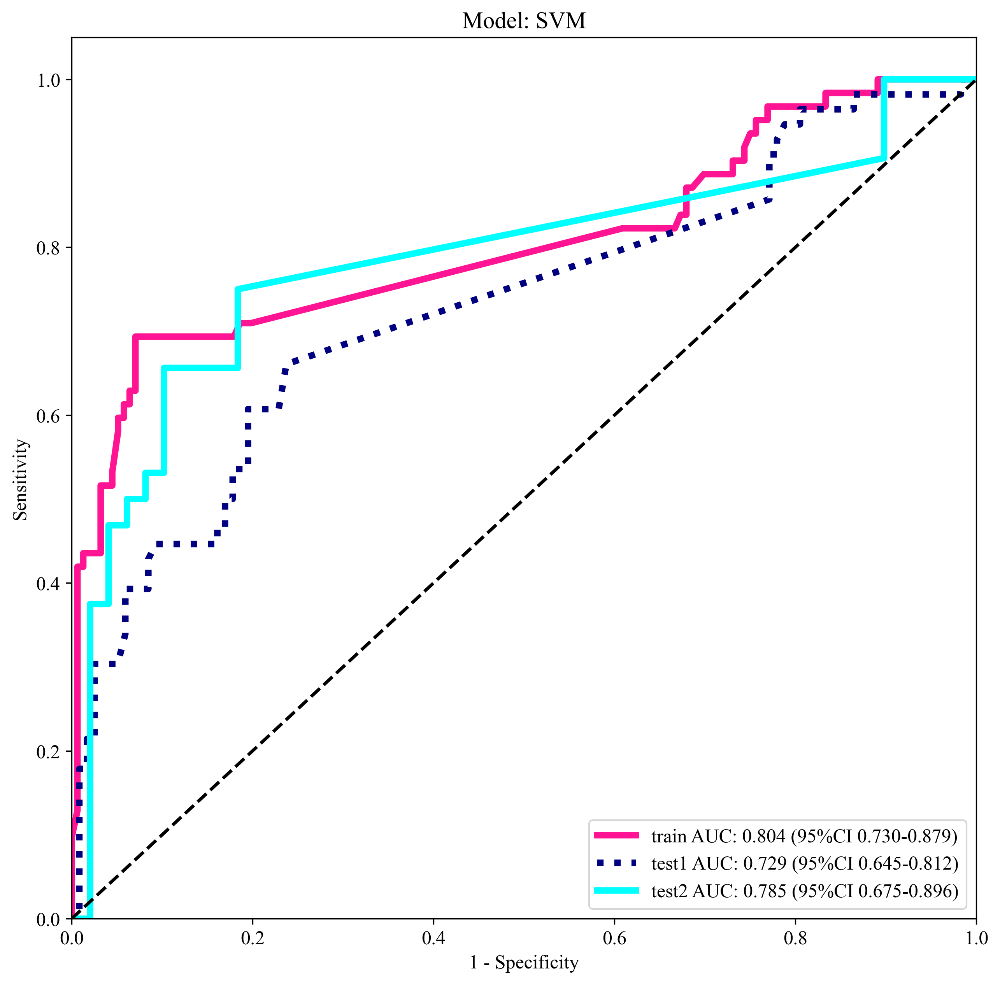

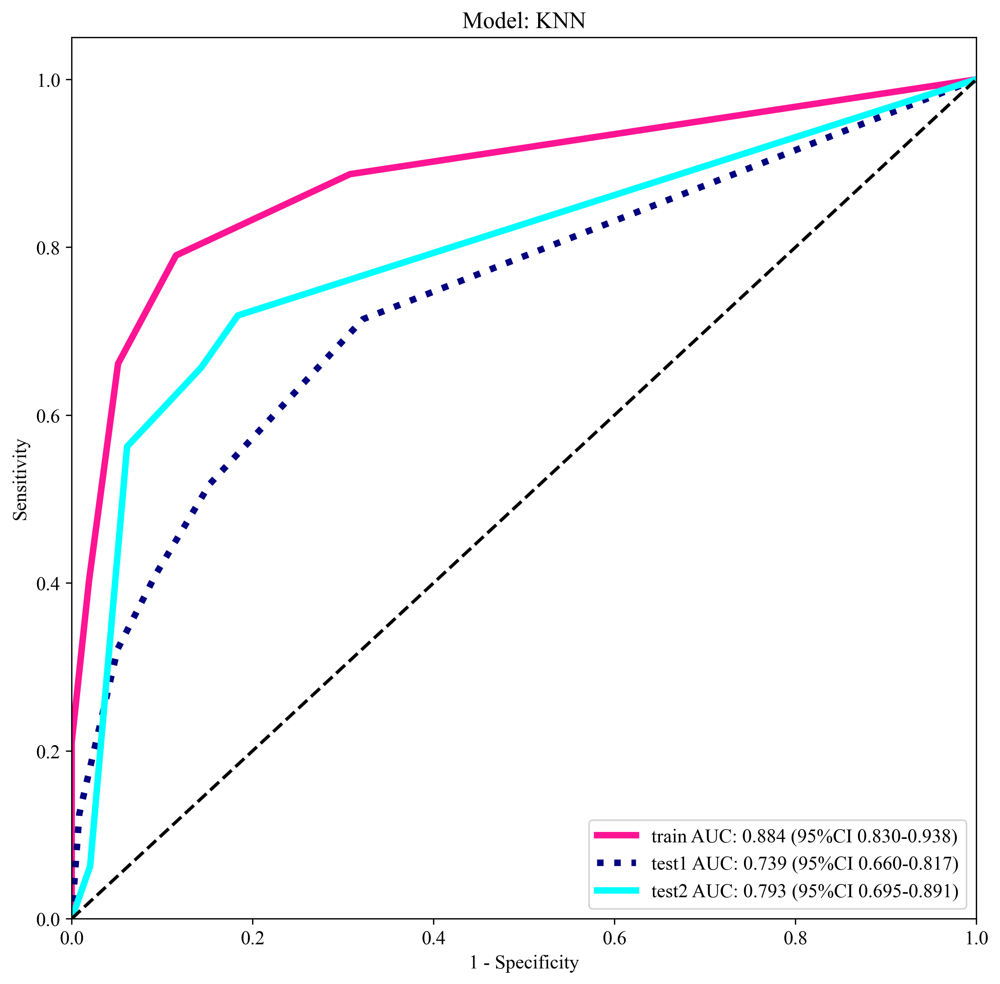

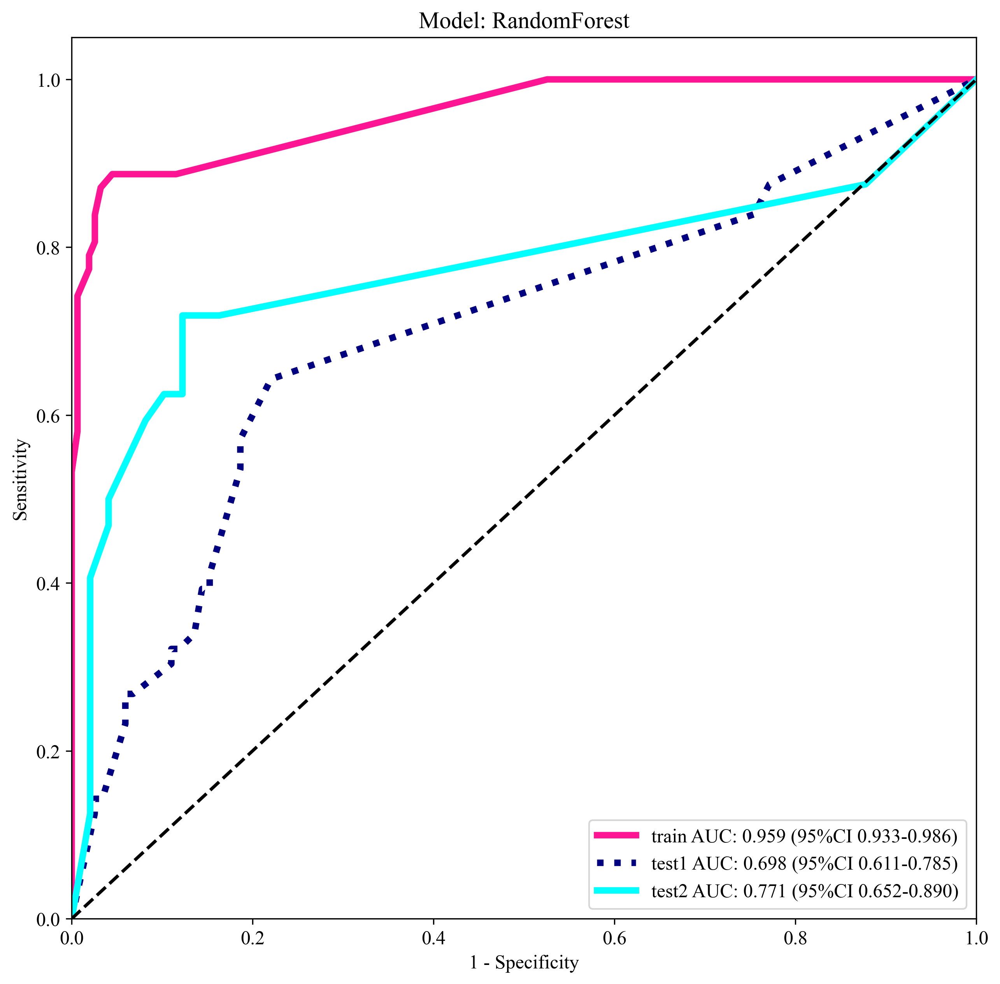

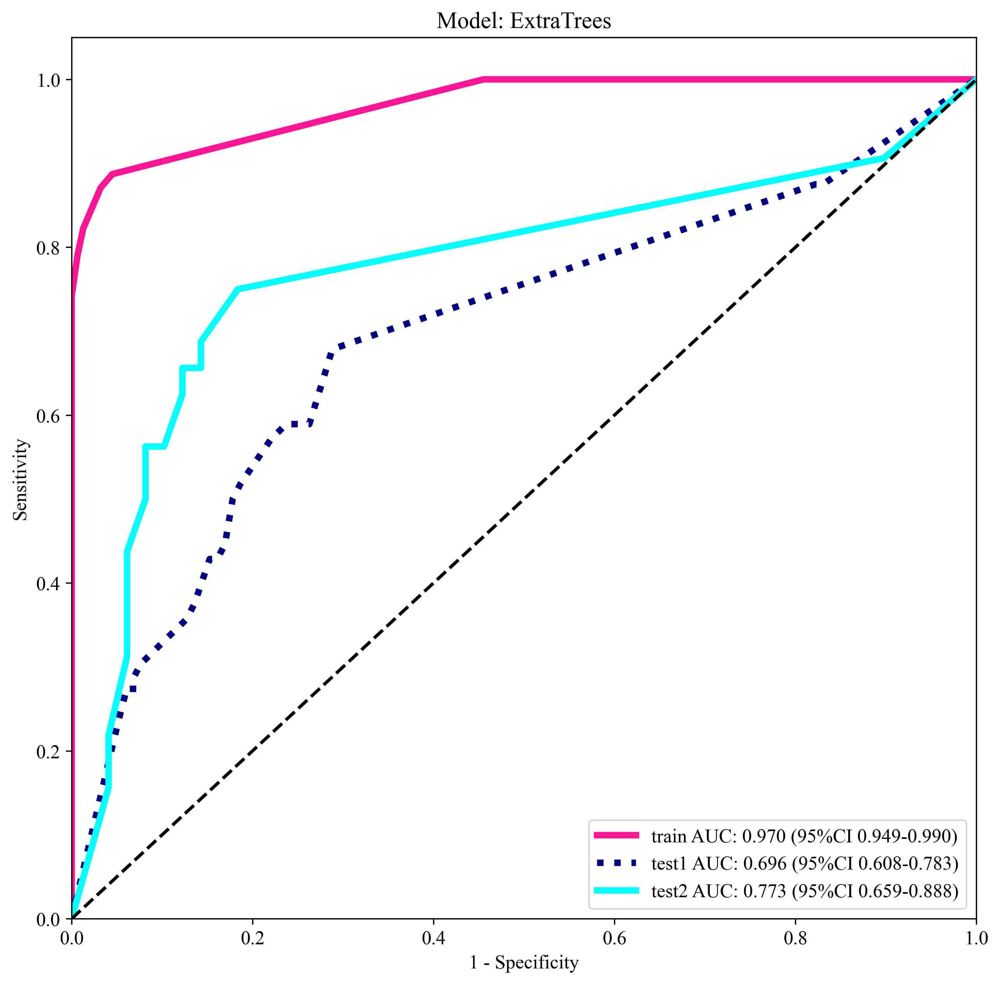

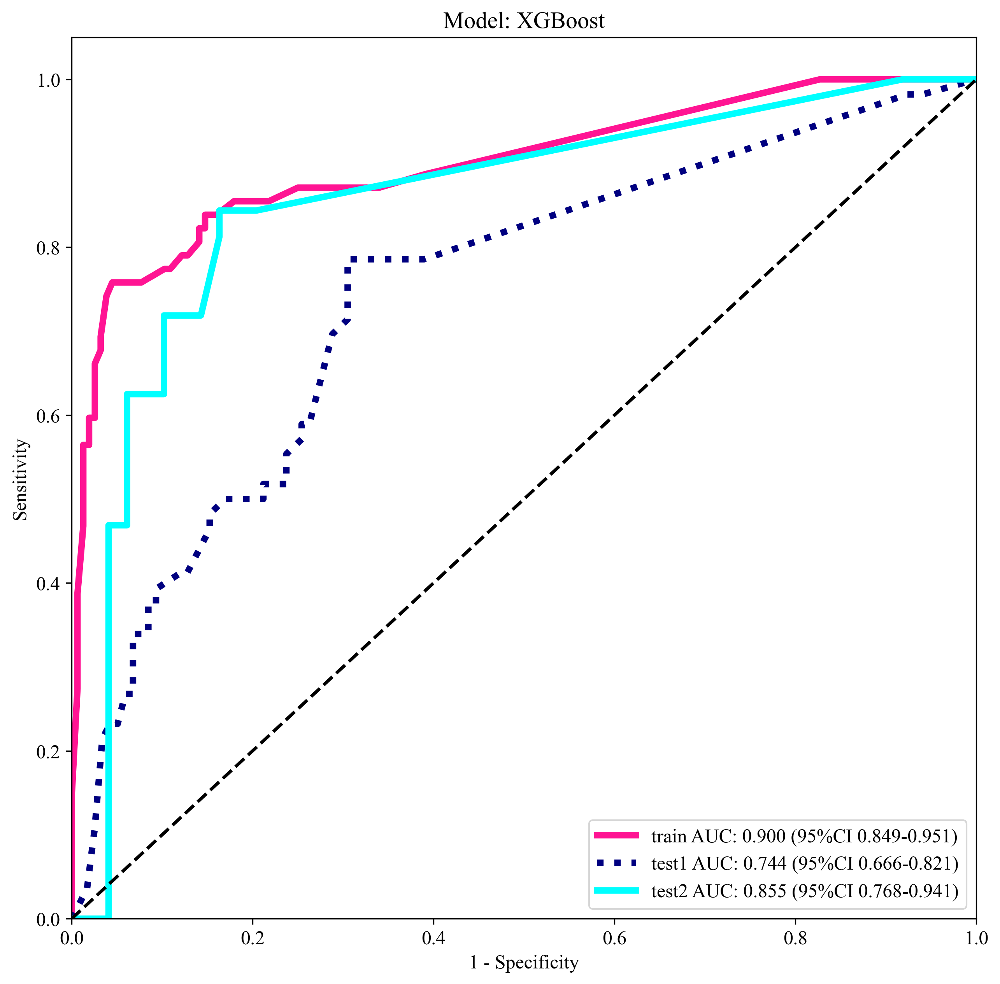

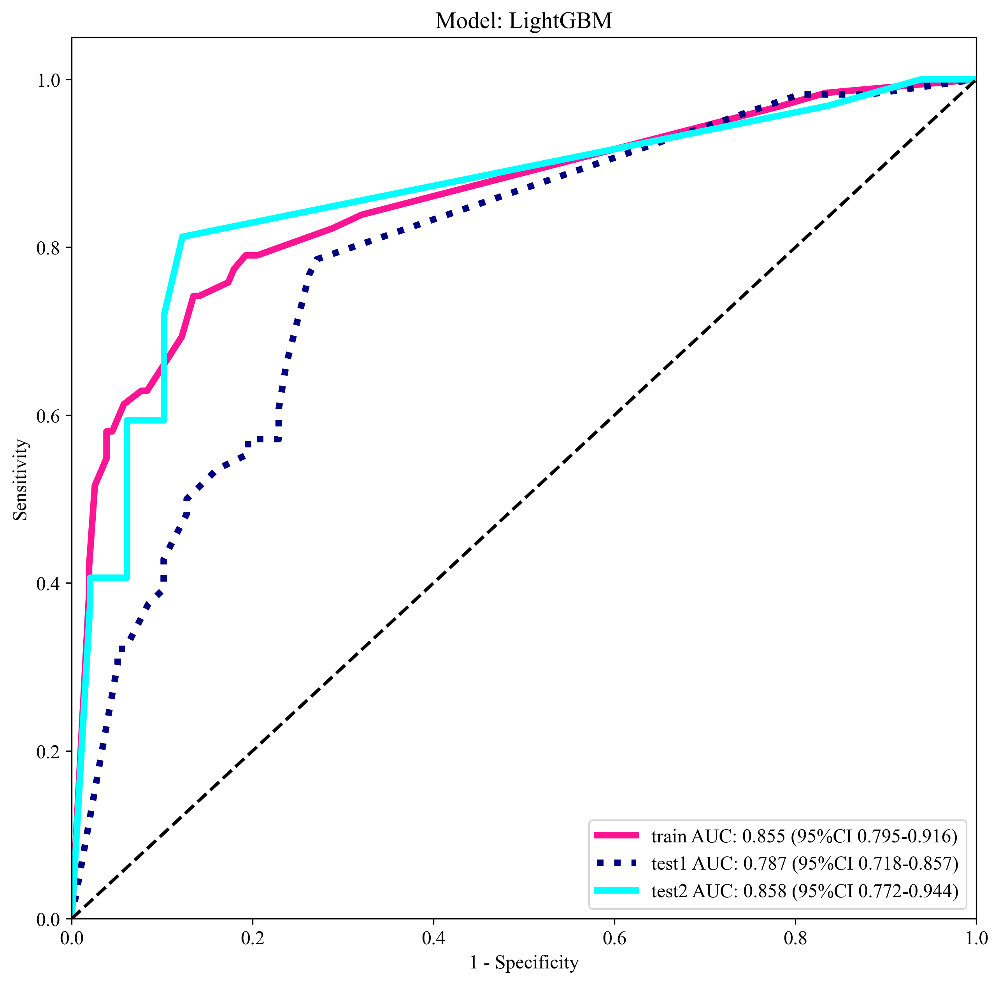

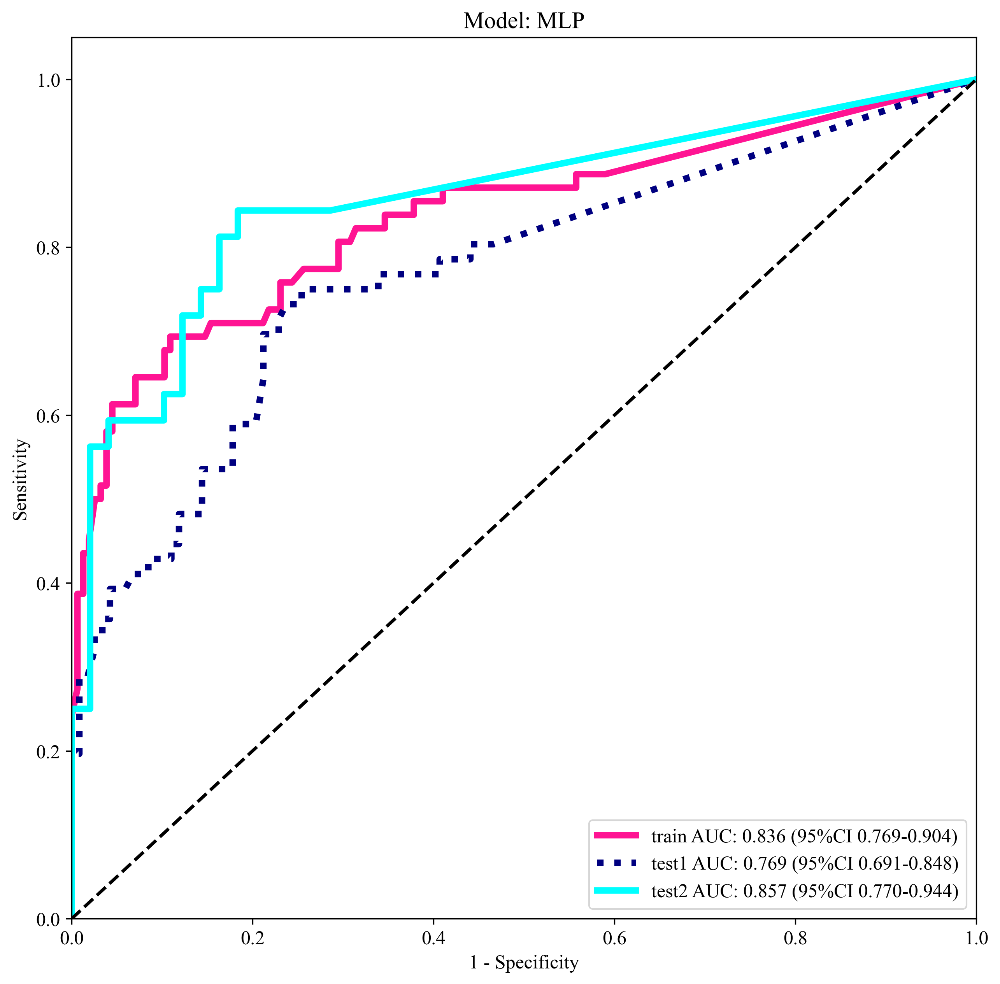

In [23]:
sel_model = model_names

for sm in sel_model:
    if sm in model_names:
        sel_model_idx = model_names.index(sm)
    
        # Plot all ROC curves
        plt.figure(figsize=(10, 10))
        for pred_score, label in zip(pred_scores, labels):
            ys = [np.array(y_train_sel[label])] + [np.array(y_val_sel[label]) for _, y_val_sel, _ in val_datasets.values()]
            ps = [pred_score[sel_model_idx][0]] + [p_[0] for p_ in pred_score[sel_model_idx][1]]
            okcomp.comp1.draw_roc(ys, ps, 
                                  labels=['train'] + list(val_datasets.keys()), title=f"Model: {sm}")
            plt.savefig(f'img/{task_type}_model_{sm}_roc.svg', bbox_inches = 'tight')
            plt.show()

#### 汇总所有模型

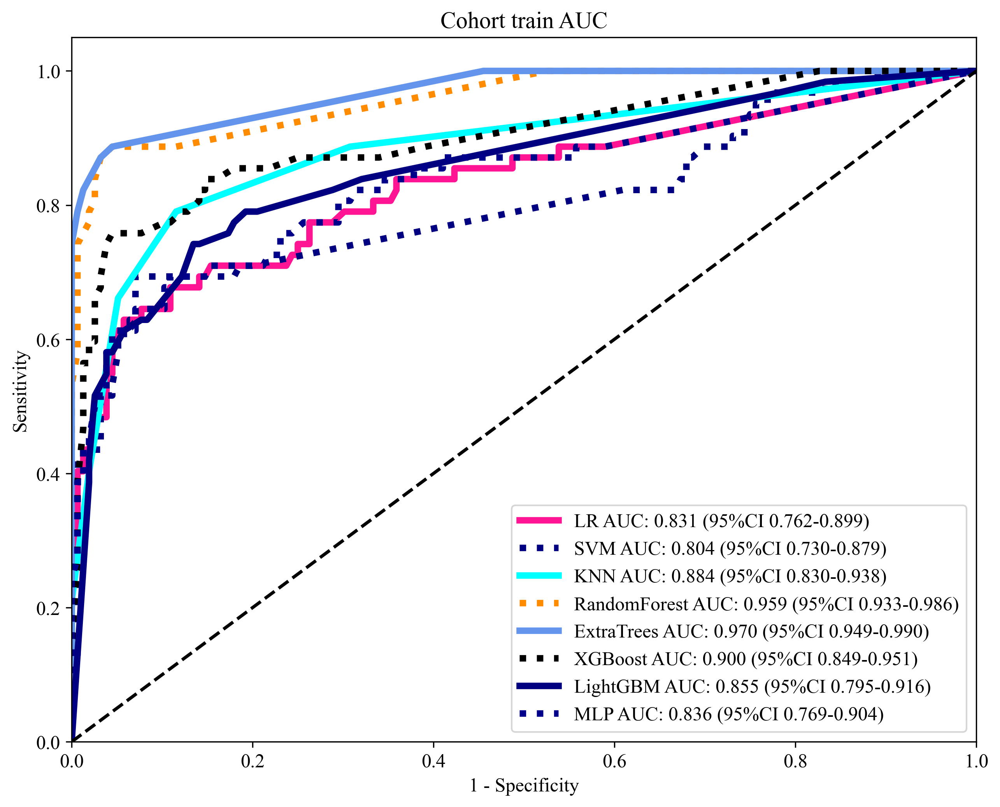

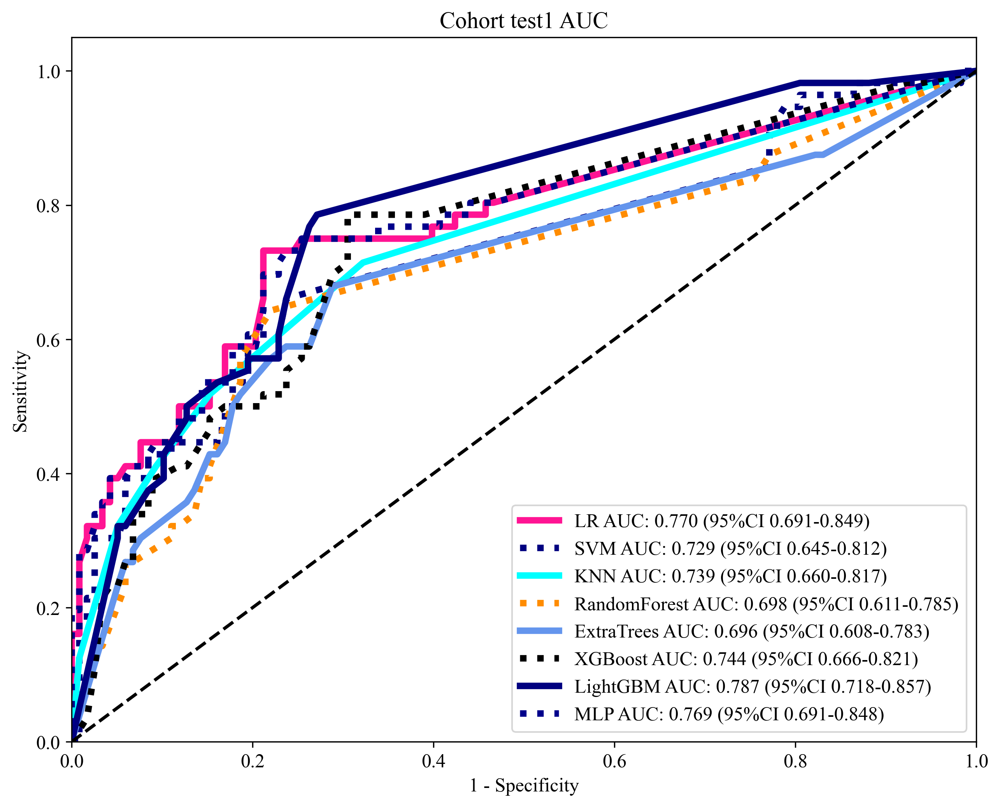

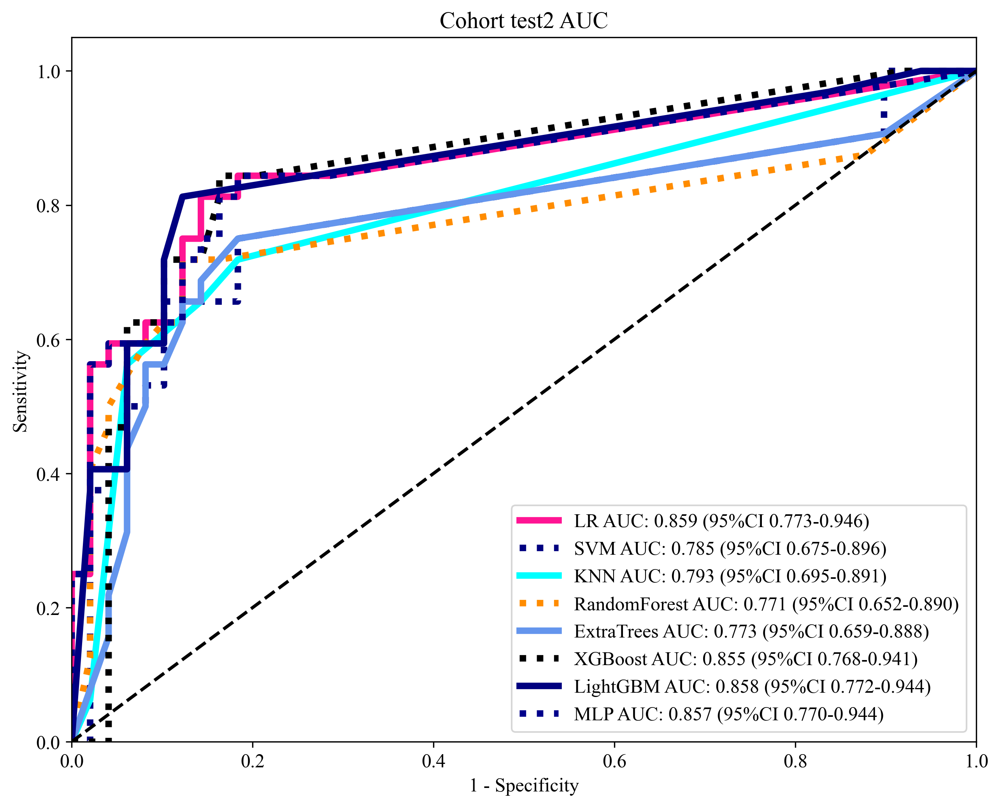

In [24]:
sel_model = model_names

for pred_score, label in zip(pred_scores, labels):
    pred_val_scores = []
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            pred_val_scores.append((pred_score[sel_model_idx][0], y_train_sel))
    p_, l_ = zip(*pred_val_scores)
    okcomp.comp1.draw_roc(l_, p_, labels=sel_model, title=f"Cohort train AUC")
    plt.savefig(f'img/{task_type}_model_train_roc.svg', bbox_inches = 'tight')
    plt.show()
    for sel_subset_idx, subset in enumerate(val_datasets.keys()):
        pred_val_scores = []
        for sm in sel_model:
            if sm in model_names:
                sel_model_idx = model_names.index(sm)
                pred_val_scores.append(pred_score[sel_model_idx][1][sel_subset_idx])
        p_, l_ = zip(*pred_val_scores)
        okcomp.comp1.draw_roc(l_, p_, labels=sel_model, title=f"Cohort {subset} AUC")
        plt.savefig(f'img/{task_type}_model_{subset}_roc.svg', bbox_inches = 'tight')
        plt.show()

### DCA 决策曲线

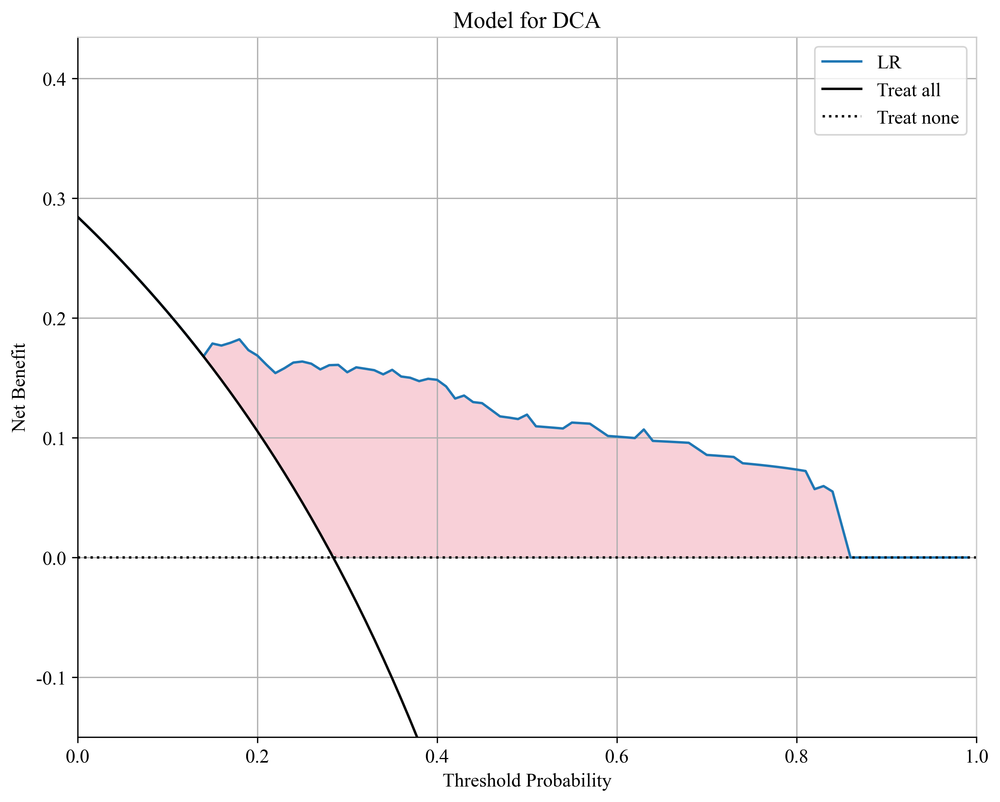

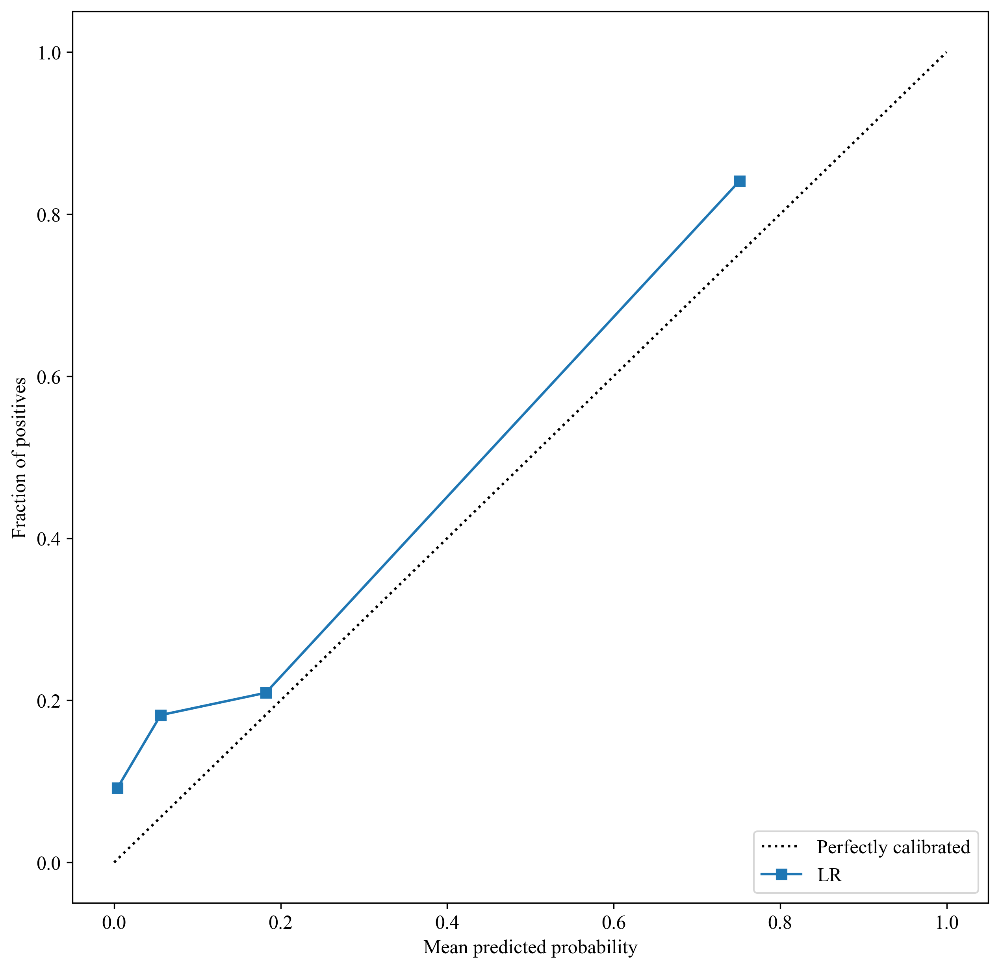

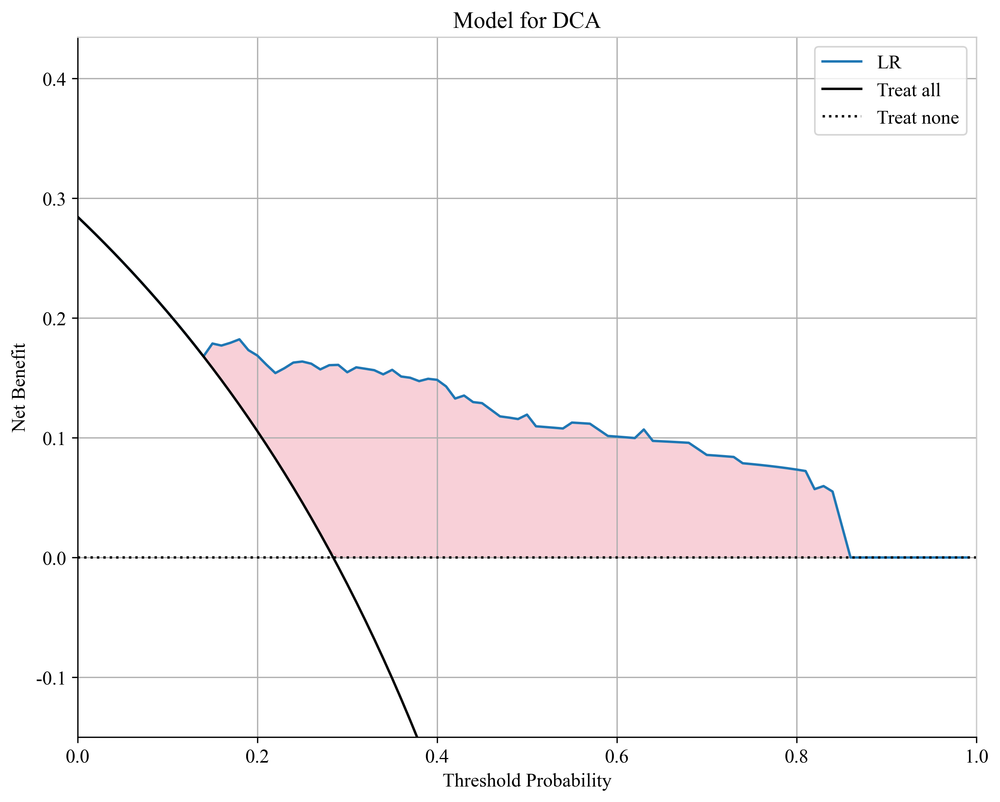

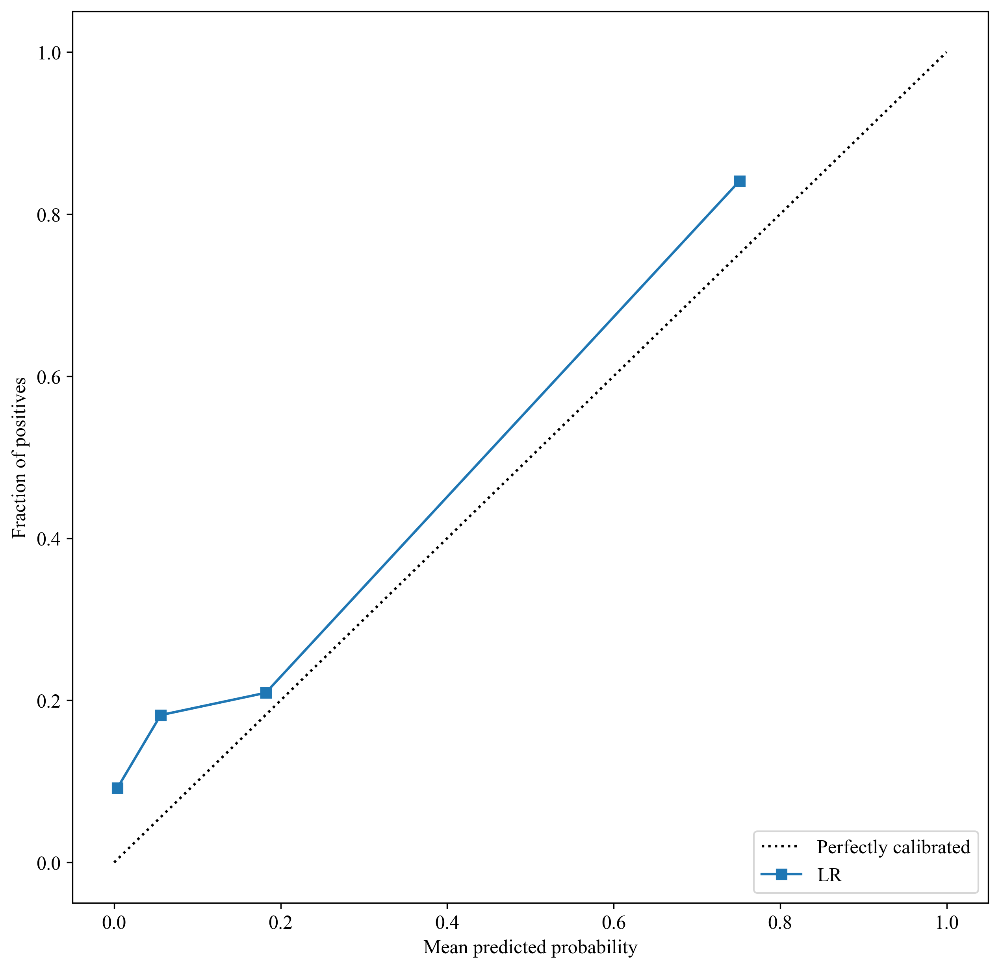

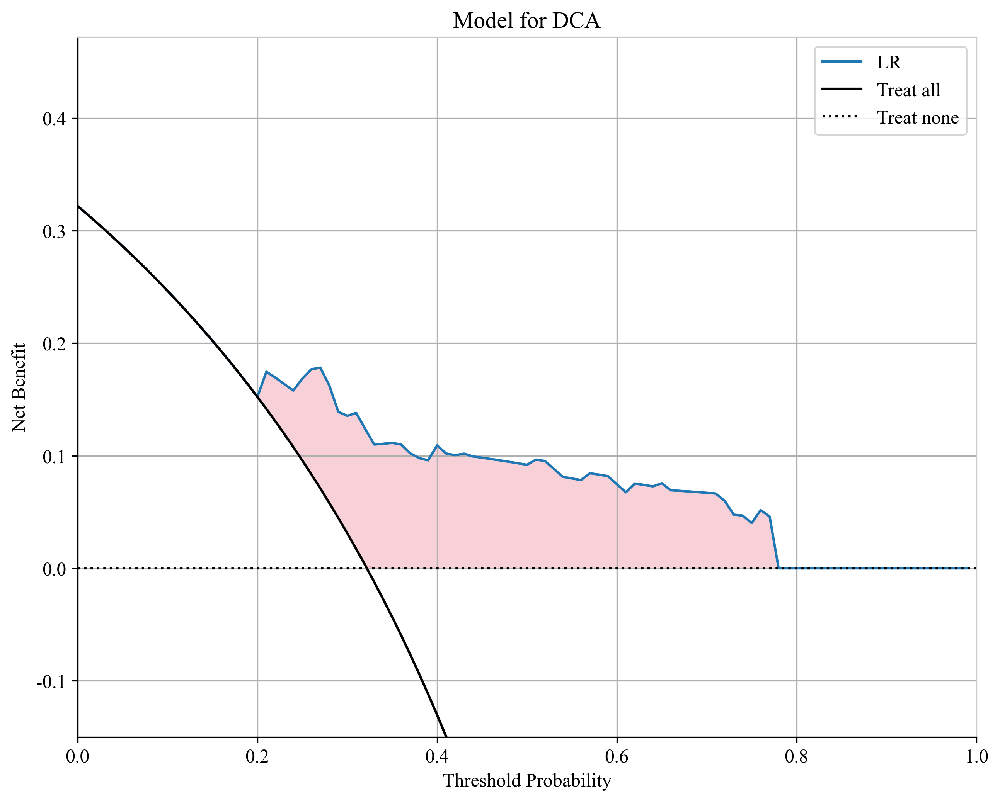

...

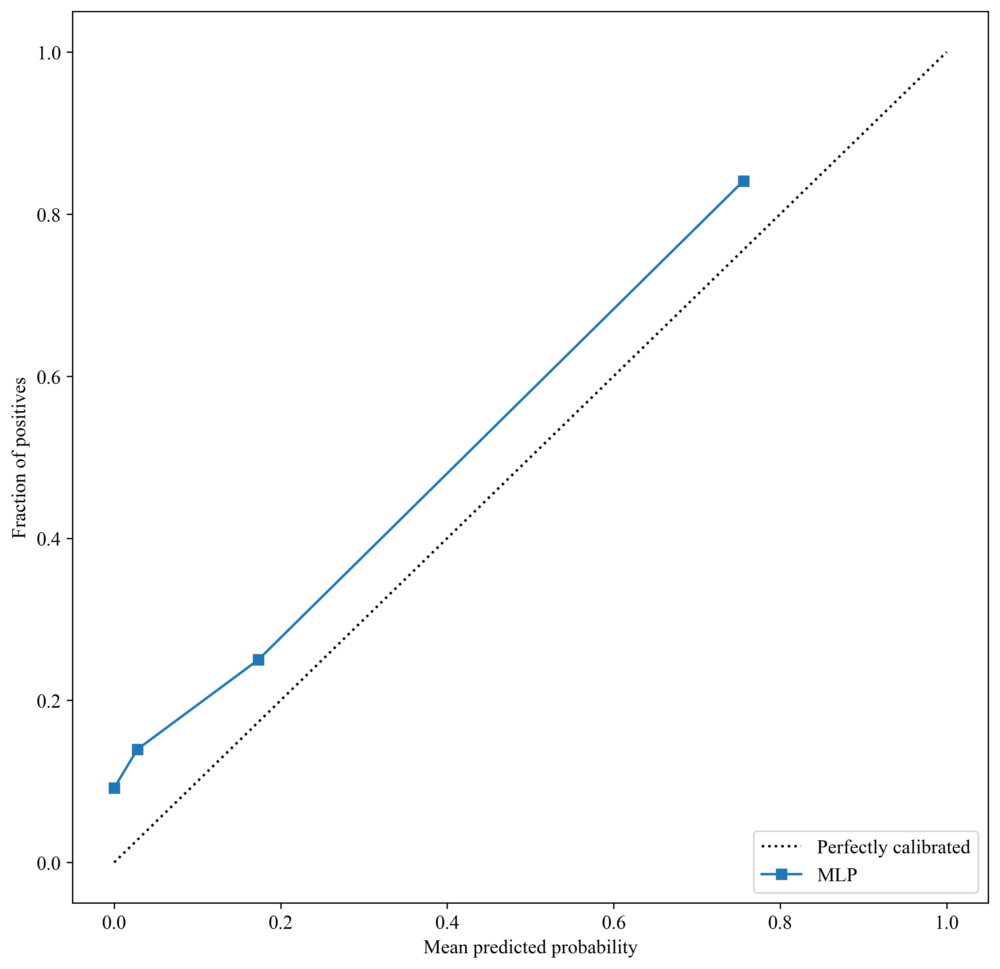

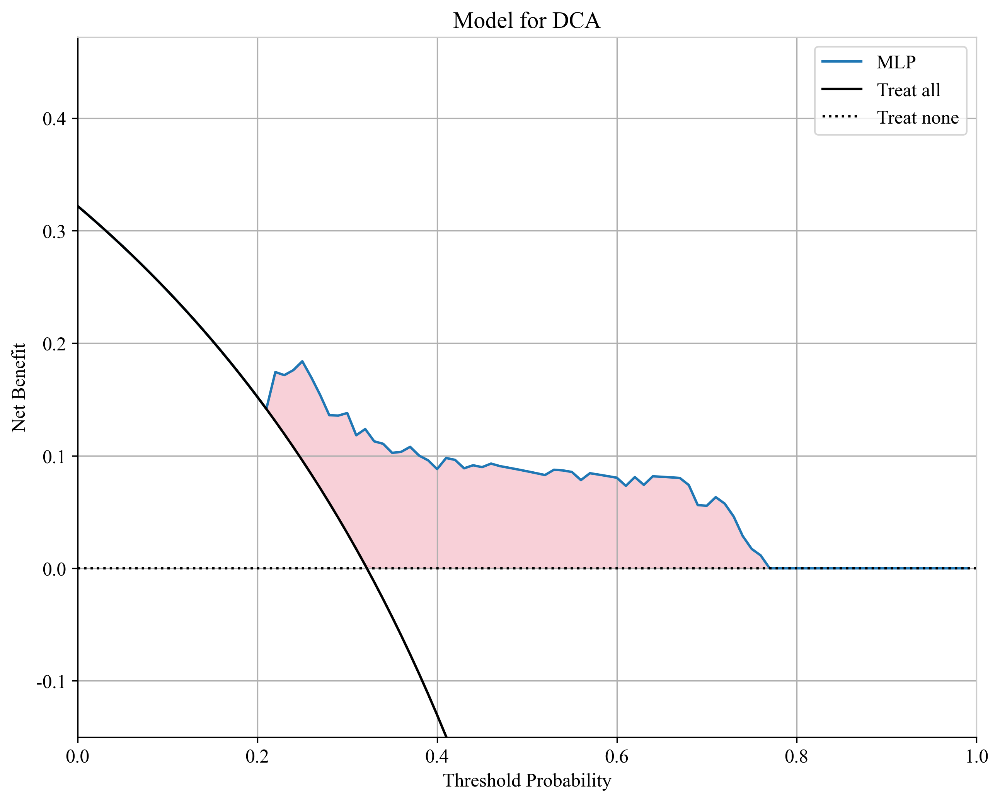

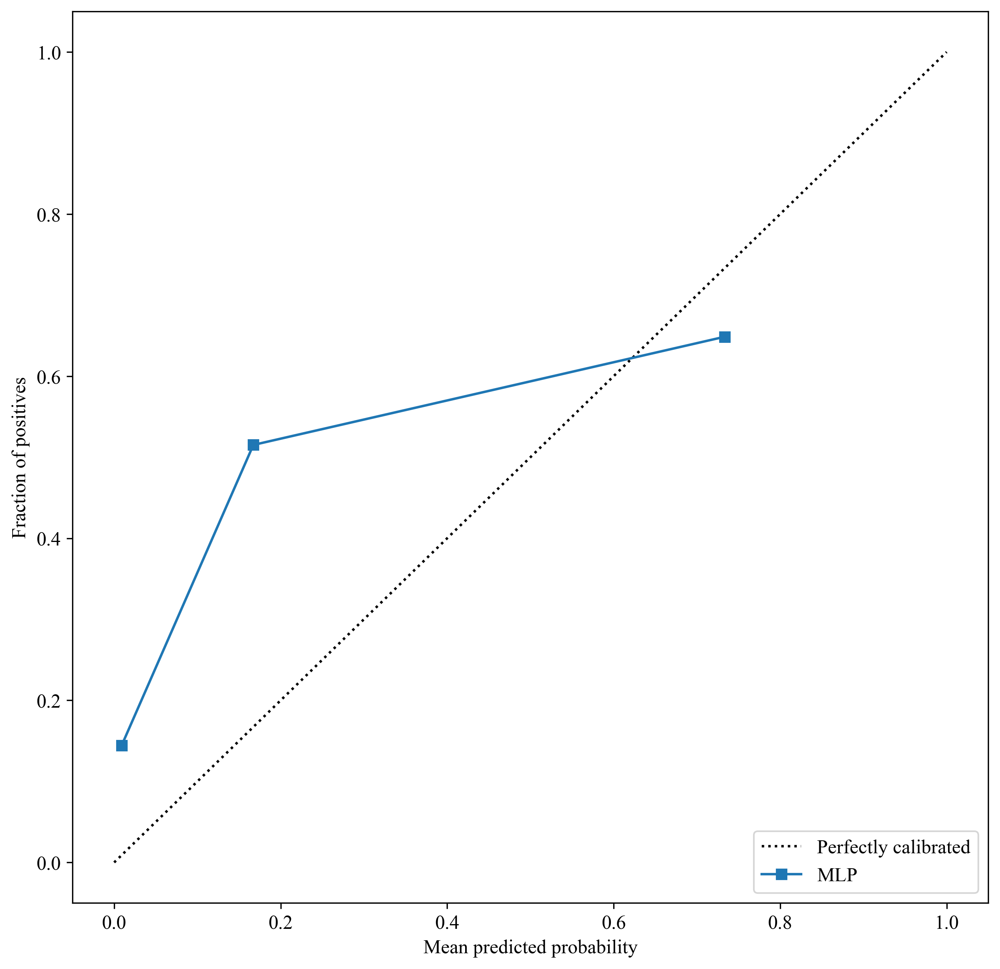

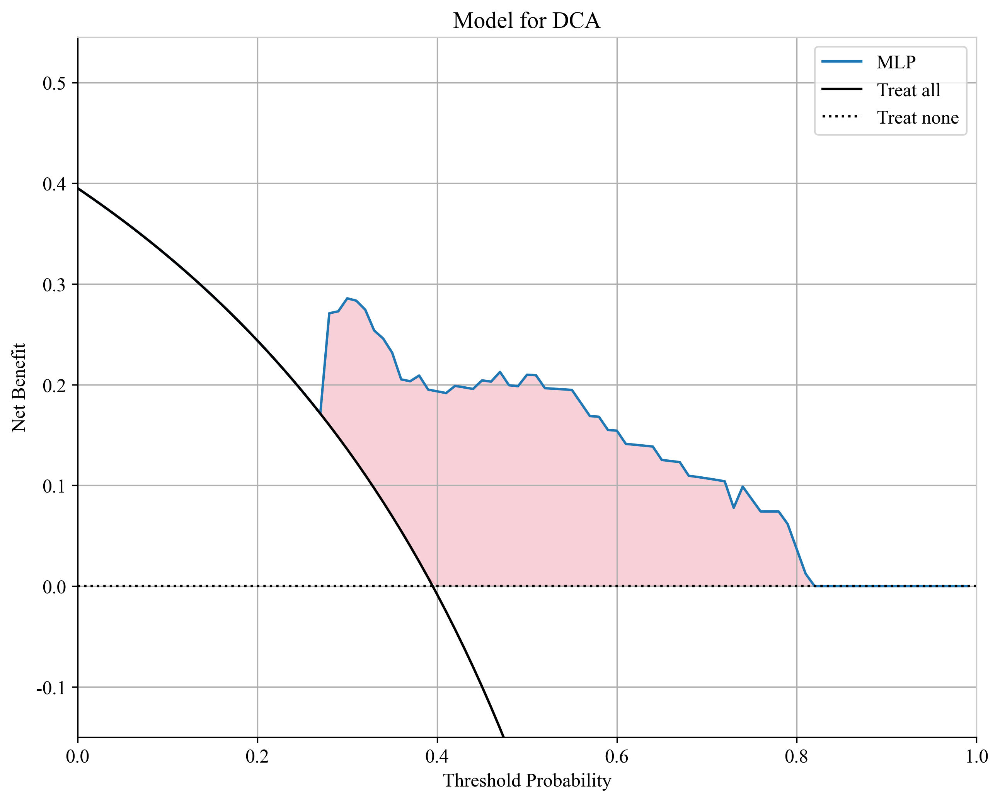

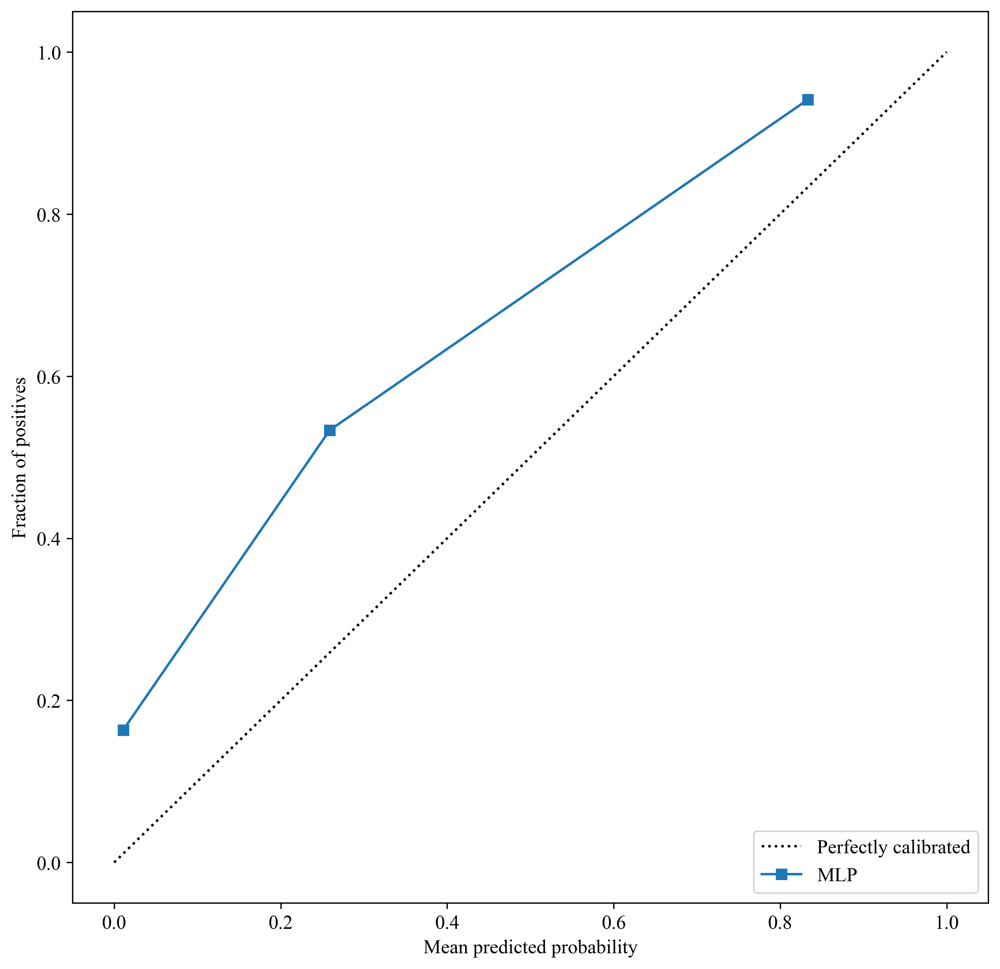

In [25]:
from onekey_algo.custom.components.comp1 import plot_DCA, draw_calibration
# 设置绘制参数
sel_model = model_names
for sm in sel_model:
    if sm in model_names:
        sel_model_idx = model_names.index(sm)
        for idx, label in enumerate(labels):
            for sel_subset_idx, subset in enumerate(val_datasets.keys()):
                p_ = pred_scores[idx][sel_model_idx][0]
                plot_DCA([p_[:, 0]], y_train_sel[label], title=f'Model for DCA', labels=sm, remap=True, y_min=-0.15, )
                plt.savefig(f'img/{task_type}_model_train_{sm}_dca.svg', bbox_inches = 'tight')
                plt.show()
                draw_calibration(pred_scores=[p_[:, 0]], n_bins=5, remap=True,
                                 y_test=[y_train_sel[label]], model_names=[sm])
                plt.savefig(f'img/{task_type}_model_train_{sm}_cali.svg', bbox_inches = 'tight')
                plt.show()
            for sel_subset_idx, subset in enumerate(val_datasets.keys()):
                p_, l_ = pred_scores[idx][sel_model_idx][1][sel_subset_idx]
                plot_DCA([p_[:, 0]], l_[label], title=f'Model for DCA', labels=sm, remap=True, y_min=-0.15, )
                plt.savefig(f'img/{task_type}_model_{subset}_{sm}_dca.svg', bbox_inches = 'tight')
                plt.show()
                draw_calibration(pred_scores=[p_[:, 0]], n_bins=5, remap=True,
                                 y_test=[l_[label]], model_names=[sm])
                plt.savefig(f'img/{task_type}_model_{subset}_{sm}_cali.svg', bbox_inches = 'tight')
                plt.show()

## 保存模型结果

可以把模型预测的标签结果以及每个类别的概率都保存下来。

In [26]:
import os
import numpy as np

os.makedirs('results', exist_ok=True)
sel_model = sel_model

all_log = []
for idx, label in enumerate(labels):
    for sm in sel_model:
        if sm in model_names:
            sel_model_idx = model_names.index(sm)
            target = targets[idx][sel_model_idx]
            # 预测训练集和测试集数据。
            train_indexes = np.reshape(np.array(train_ids), (-1, 1)).astype(str)
            # 保存预测的训练集和测试集结果
            y_train_pred_scores = target.predict_proba(X_data)
            columns = ['ID'] + [f"{label}-{i}"for i in range(y_train_pred_scores.shape[1])]
            result_train = pd.DataFrame(np.concatenate([train_indexes, y_train_pred_scores], axis=1), columns=columns)
            result_train.to_csv(f'results/{task_type}_{sm}_train.csv', index=False)
            result_train['model'] = sm
            result_train['pred_score'] = list(map(lambda x: max(x), 
                                                  np.array(result_train[['label-0', 'label-1']])))
            result_train['pred_label'] = list(map(lambda x: 0 if x[0] > x[1] else 1, 
                                                  np.array(result_train[['label-0', 'label-1']])))
            all_log.append(result_train)
            for subset, (X_val_sel, y_val_sel, val_ids) in val_datasets.items():
                val_indexes = np.reshape(np.array(val_ids), (-1, 1)).astype(str)
                y_val_pred_scores = target.predict_proba(X_val_sel)
                result_val = pd.DataFrame(np.concatenate([val_indexes, y_val_pred_scores], axis=1), columns=columns)
                result_val.to_csv(f'results/{task_type}_{sm}_{subset}.csv', index=False)
                result_val['model'] = sm
                result_val['pred_score'] = list(map(lambda x: max(x), np.array(result_val[['label-0', 'label-1']])))
                result_val['pred_label'] = list(map(lambda x: 0 if x[0] > x[1] else 1,  
                                                    np.array(result_val[['label-0', 'label-1']])))
                all_log.append(result_val)
all_log = pd.concat(all_log, axis=0)